# Доза и вероятность свиста

Ноутбук проверяет, растёт ли доля секунд со свистом, когда рядом было больше молний. Кривые «доля свистов от расстояния и времени до разряда» (ноутбук `wwlln_reader`) можно объяснить и без локальной связи: рядом с грозой чаще тропики и ночь, а там свистов больше. Здесь сравнение идёт внутри страт и против дозы из других суток.

**Свист** — вистлер. `verdict = 1` — на этой секунде свист отмечен. **Доза** — число разрядов WWLLN в радиусе 1000 км за 30 минут до текущего 5-минутного бина. Сетка накопления — 5 мин × 2° × 2°. Опорный бин — 0 молний в окрестности.

На кривых три линии. **raw** — доля `verdict=1` против дозы. **MH** — отношение к опорному бину внутри общих страт, оценка Мантеля–Хензеля. **null** — то же отношение, но доза взята из грозовой картины других суток. Главная величина — **MH / null**: во сколько раз сегодняшняя гроза поднимает долю свистов сверх климатологии этого места и времени. Интервал — блочный бутстрап по суткам, 200 реплик. Значимо, если интервал не накрывает 1.

**Сохранённый прогон.** ka1 и ka2 вместе, 255 суток, 20.01.2025–31.10.2025. У ka4 отдельно 10 суток, 21–31 августа 2025, без 22 августа. Точное окно печатает ячейка загрузки.

**Что за чем идёт**

1. Страты: широта 15° × местное время 3 ч × сезон × ночь. Доза вокруг точки под спутником. Null — сутки −3, −7 и −14. Следом средняя энергия молний при том же их числе.
2. Не держат ли верхний бин дозы одна-две страты.
3. Те же страты, null ещё и с суток +3, +7, +14. Симметрия компенсирует тренд грозовой активности внутри периода. Повтор гроз от суток к суткам остаётся в обеих оценках.
4. ka4 на этих стратах. Общих суток с ka1 и ka2 нет, прогон отдельный и с более грубыми стратами.
5. В стратах используем долготу вместо местного времени. Чтобы учесть географию - суша, океан и регион в местное время почти не входят. Симметричные лаги включены. Дальше проверки идут на этой схеме.
6. Сколько страт и секунд стоит за каждой точкой кривой.
7. Энергия при фиксированной дозе на схеме «долгота»: сначала среднее, затем медиана. Среднее тянут редкие сильные разряды. Для энергии нулевой модели нет. Затем состав: какие дозы лежат внутри сегмента энергии и какая энергия — внутри бина дозы.
8. Концентрация веса по каждой оси схемы «долгота» и разрез день/ночь.
9. Footprint и магнитно-сопряжённая точка на схеме с местным временем. Молнии ищутся у следа силовой линии, страты остаются у спутника. Лаги null — только назад.
10. ka4 на схеме «долгота».
11. Устойчивость к радиусу, длине окна и порогу ночи.
12. Footprint и магнитно-сопряжённая точка ещё раз, уже на схеме «долгота» и с симметричным null, при тех же 1000 км и 30 мин. Кривая по всем бинам дозы, не только по «≥3000».


## 4. Схема LST: широта × местное время

Первый расчёт. Страта — широта 15° × местное время 3 ч × сезон × ночь. Доза ищется вокруг точки под спутником. Null — число молний в той же ячейке сетки в сутки −3, −7 и −14. Лаг, попавший в другой сезон, пропускается.

Сравнение бина с опорным идёт по стратам, где экспозиция есть в обоих бинах. Иначе в высокий бин дозы попадают почти одни тропики, и широта возвращается в оценку. На синтетике с истинным ростом 2.0× усреднение долей по стратам давало 7×, оценка Мантеля–Хензеля — 2.0×.

Ячейка ниже копит сетку. Следующая рисует кривые ka1 и ka2, ночь и день и ту же зависимость по средней `prob_whistle`, без порога 0.5 на `verdict`. Затем — энергия при фиксированном числе молний на этих стратах.


In [2]:
%%time
# === Блок доза-эффект: самодостаточен, данные догружаются при необходимости ===
# Численный движок (сетка/доза/страты/накопители/MH) вынесен в dose_pipeline.py —
# он же переиспользуется блоком ka4, sweep-ячейками и блоком с долготой вместо LST.
import importlib

import numpy as np

import wwlln_common as wc
import dose_pipeline as dp
importlib.reload(wc)
importlib.reload(dp)

# ================= параметры =================
DOSE_R_KM = 1000.0        # радиус окрестности вокруг точки трека
DOSE_DT_MIN = 30          # «молнии за последние N минут»
GLAT, GLON, GDT_MIN = 2.0, 2.0, 5      # сетка: широта, долгота, время
STRATA_SCHEME = 'lst'     # 'lst' (широта×LST×сезон×ночь) или 'lon' (широта×долгота×сезон×ночь)

# Нулевая модель: доза из грозовой картины ДРУГИХ суток в той же точке и в тот же LST.
# Несколько лагов вместо одного: один лаг шумит и сохраняет многодневную
# персистентность гроз, из-за чего null завышается.
NULL_LAGS = (3, 7, 14)
NULL_SYMMETRIC = False    # True — добавить к обычным лагам «назад» ещё и «вперёд» (+3/+7/+14):
                          # компенсирует трендовое смещение null внутри периода оценки,
                          # но не персистентность (день+L коррелирован с днём не меньше, чем день−L)
NULL_SEASON_SAFE = True   # пропускать лаг, если день±L попал в другой календарный сезон, чем день —
                          # иначе доза «зимнего» дня подписывается как «весенняя» климатология
MAX_LAG = max(NULL_LAGS)
LOOKAHEAD = MAX_LAG if NULL_SYMMETRIC else 0
DOSE_MAX_DAYS = None      # None = все дни общего периода; число = пилот
DOSE_SC = ('ka1', 'ka2')
DO_ENERGY = True          # средняя энергия молний в окрестности
NIGHT_SZA_DEG = wc.NIGHT_SZA_DEG   # ночь на поверхности, единая по ноутбуку

# Пороги MH-анализа/бутстрапа — константы конфигурации, не результат вычислений.
# Держим их здесь (а не в ячейке MH-анализа), чтобы независимым ячейкам ниже
# (ka4, sweep, долгота, geometry) было достаточно выполнить только эту ячейку,
# не дожидаясь полного MH-анализа с бутстрапом (~1-2 мин) ради 4 чисел.
MIN_STRAT_EXP = 500     # мин. экспозиция страты в бине дозы
MIN_REPORT_EXP = 20000  # мин. экспозиция общего носителя, чтобы бин попал в сводку
N_BOOT = 200            # реплик блочного бутстрапа (блок = сутки)
REF_BIN = 0             # опорный бин: молний в окрестности нет

DOSE_EDGES = dp.DEFAULT_DOSE_EDGES
DOSE_LABELS = dp.DEFAULT_DOSE_LABELS
E_EDGES = dp.DEFAULT_E_EDGES
E_LABELS = dp.DEFAULT_E_LABELS

# Единый период: сутки, где есть все КА и файл AE. AE нужен глубже — нулевой
# модели требуются сутки за MAX_LAG до начала оценки (и после — если NULL_SYMMETRIC).
_paths_d = wc.resolve_paths()
DOSE_DAYS = wc.analysis_days(_paths_d['pred'], _paths_d['ae'], DOSE_SC)
if DOSE_MAX_DAYS is not None:
    DOSE_DAYS = DOSE_DAYS[:DOSE_MAX_DAYS]
_dc = wc.day_codes(DOSE_DAYS)
DOSE_DAYCODES = set(int(c) for c in _dc)
AE_DAYS = [str(np.datetime64(int(c), 'D')).replace('-', '')
           for c in range(int(_dc.min()) - MAX_LAG - 1, int(_dc.max()) + LOOKAHEAD + 1)]
print(f'Период оценки: {len(DOSE_DAYS)} суток ({DOSE_DAYS[0]} … {DOSE_DAYS[-1]})')

df, df_pred = wc.ensure_data(globals(), days=DOSE_DAYS, ae_days=AE_DAYS)
if 'energy' not in df.columns:
    raise ValueError('В df нет energy')

# ================= реальный период оценки =================
# Пересечение DOSE_DAYCODES с тем, что фактически оказалось в загруженных df/df_pred —
# устойчиво к случаю, когда df/df_pred уже были в памяти ядра с другим диапазоном дат.
_pts_all = df_pred['timestamp'].values
pred_days_present = set(_pts_all.astype('datetime64[D]').astype(np.int64).tolist())
ae_t_all = df['datetime'].values
ae_day0 = ae_t_all[0].astype('datetime64[D]').astype(np.int64)
ae_day1 = ae_t_all[-1].astype('datetime64[D]').astype(np.int64)
acc_days = sorted(d for d in DOSE_DAYCODES if d in pred_days_present and ae_day0 <= d <= ae_day1)
if not acc_days:
    raise ValueError('Нет суток, где есть и предсказания всех КА, и AE')
print(f'Дней с оценкой: {len(acc_days)} ({np.datetime64(acc_days[0], "D")} … '
      f'{np.datetime64(acc_days[-1], "D")})')

# ================= накопление =================
accum = dp.run_accumulation(
    df, df_pred, sc_list=DOSE_SC, acc_days=acc_days,
    dose_r_km=DOSE_R_KM, dose_dt_min=DOSE_DT_MIN,
    glat=GLAT, glon=GLON, gdt_min=GDT_MIN,
    null_lags=NULL_LAGS, null_symmetric=NULL_SYMMETRIC, null_season_safe=NULL_SEASON_SAFE,
    do_energy=DO_ENERGY, night_sza_deg=NIGHT_SZA_DEG, strata_scheme=STRATA_SCHEME,
    dose_edges=DOSE_EDGES, e_edges=E_EDGES,
)

# короткие имена для ячеек ниже (график/сводка/диагностика)
exp_true_d, pos_true_d, prb_true_d = accum['exp_true_d'], accum['pos_true_d'], accum['prb_true_d']
exp_null_d, pos_null_d, prb_null_d = accum['exp_null_d'], accum['pos_null_d'], accum['prb_null_d']
exp_en_d, pos_en_d = accum['exp_en_d'], accum['pos_en_d']
N_DOSE, N_EB = accum['n_dose'], accum['n_eb']
N_SC = accum['n_sc']
N_LATB, N_HOURB, N_SEA, N_NIGHT = accum['n_latb'], accum['n_axis4'], accum['n_sea'], accum['n_night']
season_order_d = list(wc.SEASON_ORDER)


Период оценки: 255 суток (20250120 … 20251031)
df не найден — загружаю молнии
AE из кэша: /Users/user/Downloads/wwlln/cache/AE_20250101_20251231.parquet
df_pred не найден — загружаю предсказания
ka1: 255 файлов из /Users/user/Downloads/wwlln/whistler_binary/ka1
ka2: 255 файлов из /Users/user/Downloads/wwlln/whistler_binary/ka2
Дней с оценкой: 255 (2025-01-20 … 2025-10-31)
Накопители: 161 МБ; сетки строим для 300 дней (схема страт='lst', лаги=(3, 7, 14) назад, сезонный фильтр=вкл)
  ... 20/300 дней
  ... 40/300 дней
  ... 60/300 дней
  ... 80/300 дней
  ... 100/300 дней
  ... 120/300 дней
  ... 140/300 дней
  ... 160/300 дней
  ... 180/300 дней
  ... 200/300 дней
  ... 220/300 дней
  ... 240/300 дней
  ... 260/300 дней
  ... 280/300 дней
  ... 300/300 дней
Готово. Экспозиция: 41,985,036 сэмплов, verdict=1: 3,816,529 (9.09%); экспозиция null: 118,012,442 (в среднем 2.81 лага/сутки использовано из 3 возможных)
CPU times: user 5min 47s, sys: 2min 49s, total: 8min 37s
Wall time: 9min 8s


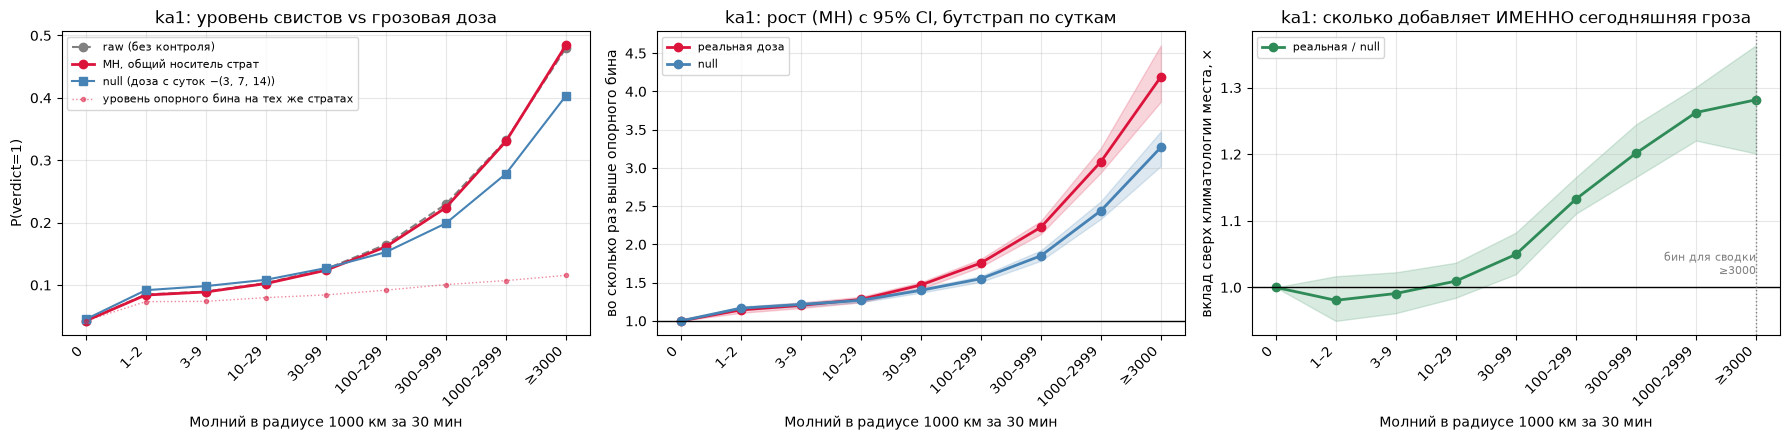

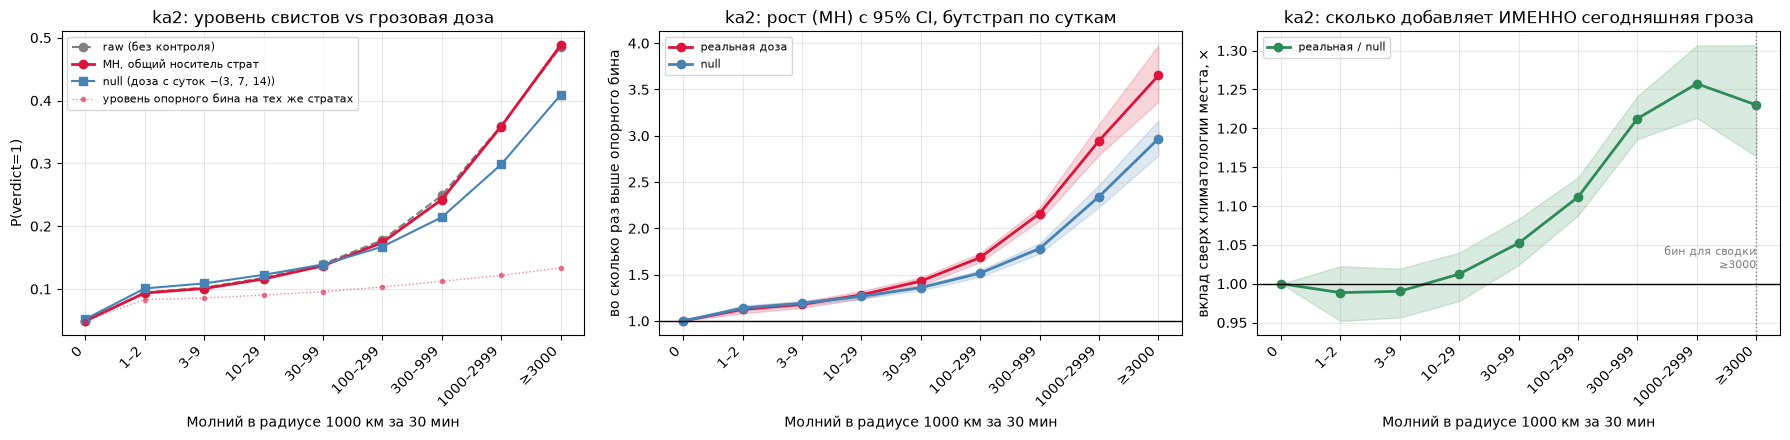

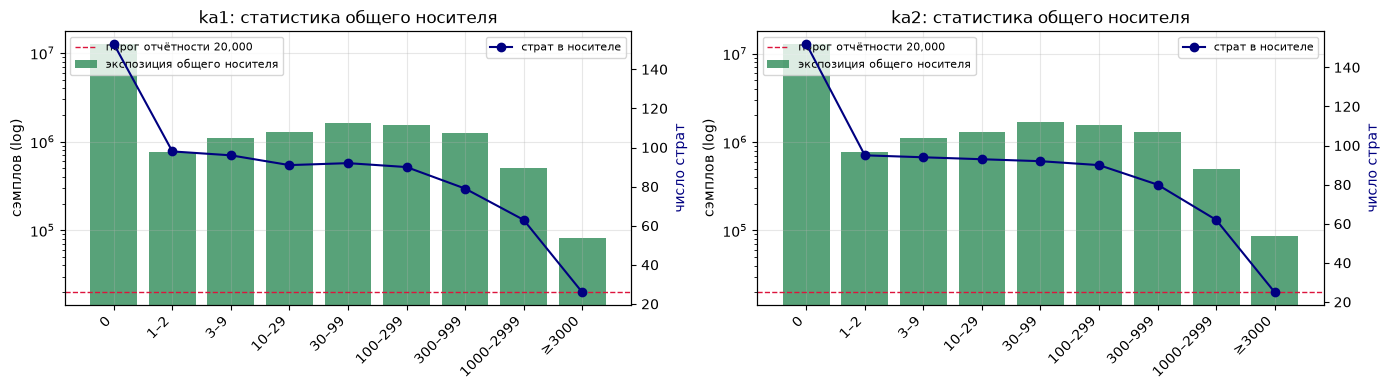

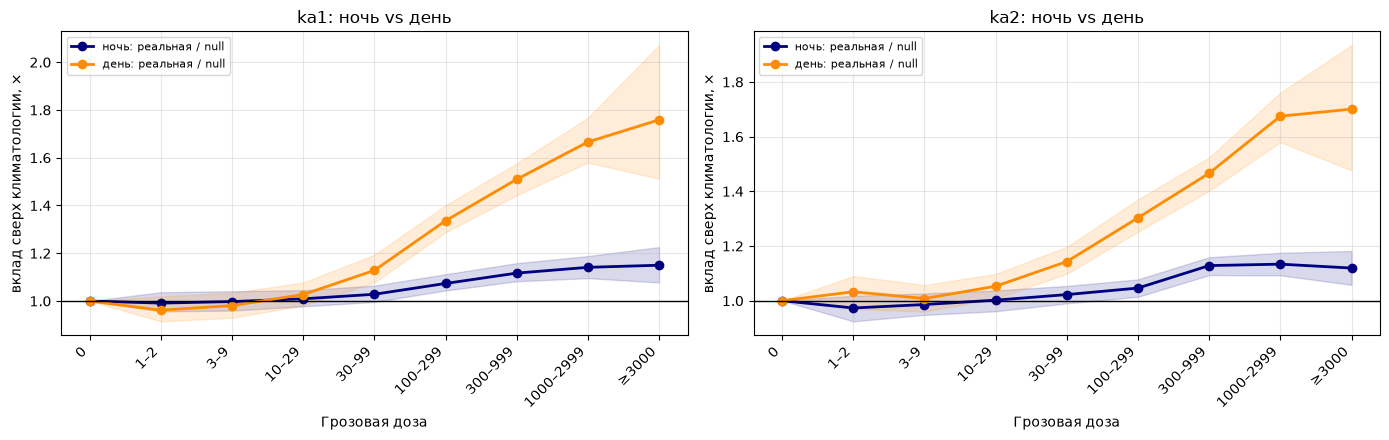

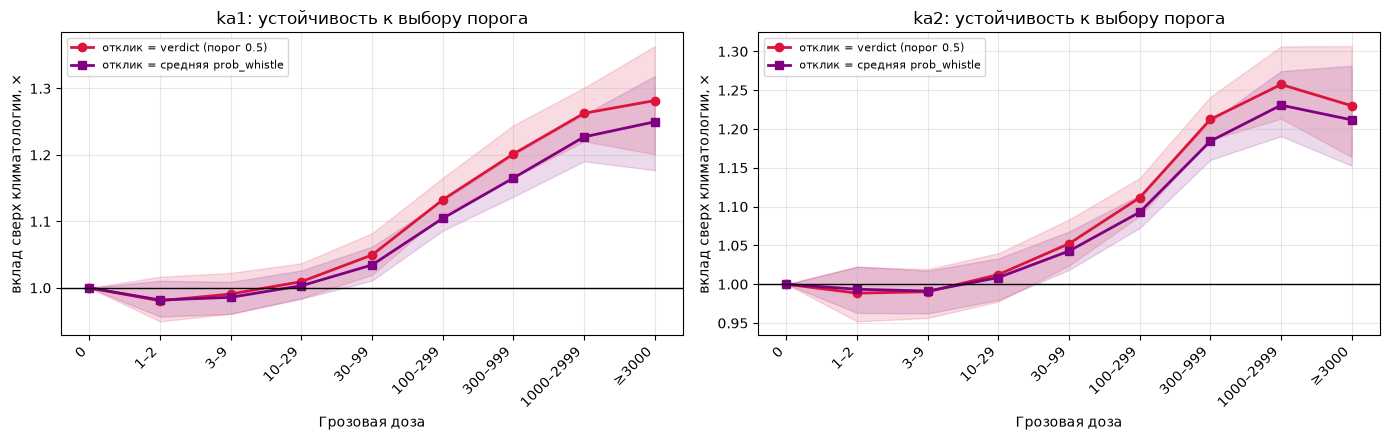

In [2]:
import warnings

import matplotlib.pyplot as plt

import dose_pipeline as dp

# MIN_STRAT_EXP/MIN_REPORT_EXP/N_BOOT/REF_BIN теперь объявлены в ячейке загрузки
# (94583c9b) — здесь только используются, чтобы не требовать перезапуска этой
# ячейки ради 4 констант, если нужен только основной блок ka4/sweep/долгота/geometry.

# Сама математика (MH, бутстрап, общий носитель) теперь в dose_pipeline.py —
# здесь только тонкие обёртки, чтобы остальной код ячейки (циклы, графики) не менять.


def _strata(a, sc=None, night=None, day_axis=False):
    return dp.select_strata(a, sc=sc, night=night, day_axis=day_axis)


def _mh(E, P, ref=REF_BIN, min_exp=MIN_STRAT_EXP):
    return dp.mh(E, P, ref=ref, min_exp=min_exp)


def _pooled(E, P):
    return dp.pooled(E, P)


def analyze(sc=None, night=None, outcome='verdict', n_boot=N_BOOT, seed=0):
    return dp.analyze(accum, sc=sc, night=night, outcome=outcome, n_boot=n_boot, seed=seed,
                      ref_bin=REF_BIN, min_strat_exp=MIN_STRAT_EXP)


def report_bin(res, min_exp=MIN_REPORT_EXP, min_strata=5):
    return dp.report_bin(res, min_exp=min_exp, min_strata=min_strata, ref_bin=REF_BIN)


x = np.arange(N_DOSE)
RES = {}
for si, sc in enumerate(DOSE_SC):
    RES[sc] = analyze(sc=si)
    r = RES[sc]
    rb = report_bin(r)

    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

    axes[0].plot(x, r['raw'], 'o--', color='gray', lw=1.5, label='raw (без контроля)')
    axes[0].plot(x, r['pk_t'], 'o-', color='crimson', lw=2, label='MH, общий носитель страт')
    axes[0].plot(x, r['pk_n'], 's-', color='steelblue', label=f'null (доза с суток −{NULL_LAGS})')
    axes[0].plot(x, r['p0_t'], '.:', color='crimson', alpha=0.5, lw=1,
                 label='уровень опорного бина на тех же стратах')
    axes[0].set_ylabel('P(verdict=1)')
    axes[0].set_title(f'{sc}: уровень свистов vs грозовая доза')

    for key, ci, color, lab in [('rr_t', 'ci_t', 'crimson', 'реальная доза'),
                                ('rr_n', 'ci_n', 'steelblue', 'null')]:
        axes[1].plot(x, r[key], 'o-', color=color, lw=2, label=lab)
        axes[1].fill_between(x, r[ci][0], r[ci][1], color=color, alpha=0.18)
    axes[1].axhline(1.0, color='k', lw=1)
    axes[1].set_ylabel('во сколько раз выше опорного бина')
    axes[1].set_title(f'{sc}: рост (MH) с 95% CI, бутстрап по суткам')

    axes[2].plot(x, r['rrr'], 'o-', color='seagreen', lw=2, label='реальная / null')
    axes[2].fill_between(x, r['ci_rrr'][0], r['ci_rrr'][1], color='seagreen', alpha=0.18)
    axes[2].axhline(1.0, color='k', lw=1)
    if rb is not None:
        axes[2].axvline(rb, color='gray', ls=':', lw=1)
        axes[2].annotate(f'бин для сводки\n{DOSE_LABELS[rb]}', (rb, 1.02), fontsize=8,
                         color='gray', ha='right')
    axes[2].set_ylabel('вклад сверх климатологии места, ×')
    axes[2].set_title(f'{sc}: сколько добавляет ИМЕННО сегодняшняя гроза')

    for ax in axes:
        ax.set_xticks(x)
        ax.set_xticklabels(DOSE_LABELS, rotation=45, ha='right')
        ax.set_xlabel(f'Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

# --- сколько статистики стоит за каждой точкой ---
fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4), squeeze=False)
for si, sc in enumerate(DOSE_SC):
    ax = axes[0, si]
    r = RES[sc]
    ax.bar(x, r['expo'], color='seagreen', alpha=0.8, label='экспозиция общего носителя')
    ax.axhline(MIN_REPORT_EXP, color='crimson', ls='--', lw=1,
               label=f'порог отчётности {MIN_REPORT_EXP:,}')
    ax.set_yscale('log')
    ax.set_ylabel('сэмплов (log)')
    ax2 = ax.twinx()
    ax2.plot(x, r['nst'], 'o-', color='navy', lw=1.5, label='страт в носителе')
    ax2.set_ylabel('число страт', color='navy')
    ax.set_xticks(x)
    ax.set_xticklabels(DOSE_LABELS, rotation=45, ha='right')
    ax.set_title(f'{sc}: статистика общего носителя')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='upper left')
    ax2.legend(fontsize=8, loc='upper right')
fig.tight_layout()
plt.show()
plt.close(fig)

# --- ночь / день ---
fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5), squeeze=False)
for si, sc in enumerate(DOSE_SC):
    ax = axes[0, si]
    for ni, lab, color in [(1, 'ночь', 'navy'), (0, 'день', 'darkorange')]:
        r = analyze(sc=si, night=ni)
        RES[(sc, lab)] = r
        ax.plot(x, r['rrr'], 'o-', color=color, lw=2, label=f'{lab}: реальная / null')
        ax.fill_between(x, r['ci_rrr'][0], r['ci_rrr'][1], color=color, alpha=0.15)
    ax.axhline(1.0, color='k', lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels(DOSE_LABELS, rotation=45, ha='right')
    ax.set_xlabel('Грозовая доза')
    ax.set_ylabel('вклад сверх климатологии, ×')
    ax.set_title(f'{sc}: ночь vs день')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

# --- отклик без порога: средняя prob_whistle вместо доли verdict=1 ---
fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5), squeeze=False)
for si, sc in enumerate(DOSE_SC):
    ax = axes[0, si]
    rv = RES[sc]
    rp = analyze(sc=si, outcome='prob')
    RES[(sc, 'prob')] = rp
    ax.plot(x, rv['rrr'], 'o-', color='crimson', lw=2, label='отклик = verdict (порог 0.5)')
    ax.fill_between(x, rv['ci_rrr'][0], rv['ci_rrr'][1], color='crimson', alpha=0.15)
    ax.plot(x, rp['rrr'], 's-', color='purple', lw=2, label='отклик = средняя prob_whistle')
    ax.fill_between(x, rp['ci_rrr'][0], rp['ci_rrr'][1], color='purple', alpha=0.15)
    ax.axhline(1.0, color='k', lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels(DOSE_LABELS, rotation=45, ha='right')
    ax.set_xlabel('Грозовая доза')
    ax.set_ylabel('вклад сверх климатологии, ×')
    ax.set_title(f'{sc}: устойчивость к выбору порога')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)


### Энергия при фиксированной дозе — схема LST

Средняя энергия молний в той же окрестности 1000 км / 30 мин, отдельно внутри каждого бина дозы. Вопрос: при одном и том же числе разрядов меняется ли доля свистов, если эти разряды мощнее. Сегменты: <2 кДж, 2–6 кДж, ≥6 кДж. Нулевой модели для энергии нет. Тот же вопрос на схеме «долгота» пересчитан ниже, сначала для среднего, затем для медианы.


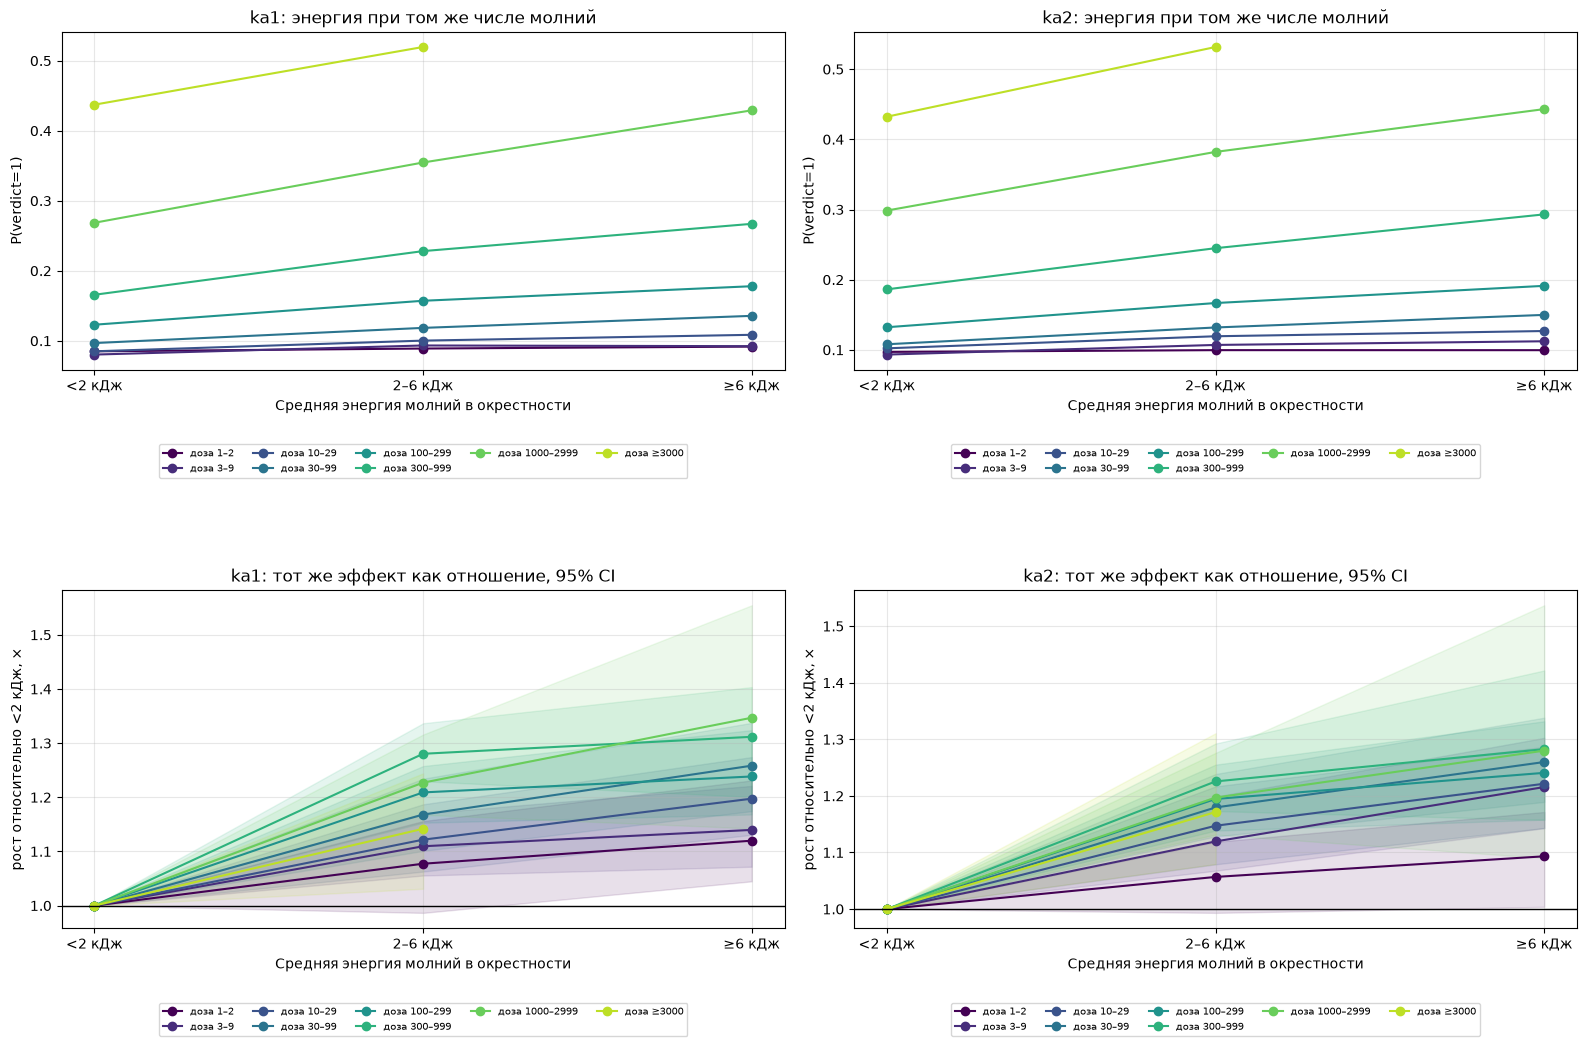

,КА,условия,бин дозы,экспозиция,страт,P(опорный),P(бин),рост MH,CI рост,рост null,сверх null,CI сверх null,рост raw
0,ka1,все,≥3000,81630,26,0.116,0.484,4.192,3.87–4.60,3.271,1.282,1.20–1.36,11.292000
1,ka1,ночь,≥3000,53779,16,0.157,0.495,3.147,2.89–3.37,2.737,1.150,1.08–1.23,6.728000
2,ka1,день,≥3000,27851,10,0.042,0.465,11.117,9.78–12.33,6.321,1.759,1.51–2.07,20.695000
3,ka2,все,≥3000,86127,25,0.134,0.488,3.651,3.37–3.98,2.968,1.230,1.16–1.31,9.862000
4,ka2,ночь,≥3000,58207,17,0.174,0.489,2.805,2.61–3.04,2.506,1.119,1.06–1.18,6.091000
5,ka2,день,≥3000,27920,8,0.056,0.487,8.656,7.35–9.78,5.089,1.701,1.48–1.93,16.665001


R=1000 км, Δt=30 мин (окно кончается текущим 5-мин бином), дней=255, null-лаги=(3, 7, 14) сут, MIN_STRAT_EXP=500, ночь: SZA>98°, бутстрап: 200 реплик по суткам
«рост MH» — сравнение внутри одинаковых страт (широта×LST×сезон×ночь).
«сверх null» — во сколько раз сегодняшняя гроза добавляет к тому, что даёт
одна лишь климатология места: значимо, если CI не накрывает 1.0.


In [3]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd


def analyze_energy(si, db, n_boot=N_BOOT, seed=0):
    """Эффект средней энергии молний при ФИКСИРОВАННОМ их числе (бин дозы db).
    Контроль здесь — сама фиксация дозы плюс страты; нулевой модели нет."""
    E = _strata(exp_en_d[..., db, :], sc=si, day_axis=True)
    P = _strata(pos_en_d[..., db, :], sc=si, day_axis=True)
    rr, p_ref, p_k, nst, expo = _mh(E.sum(axis=0), P.sum(axis=0))
    rng = np.random.default_rng(seed)
    nd = E.shape[0]
    bs = np.full((n_boot, E.shape[2]), np.nan)
    for b in range(n_boot):
        c = np.bincount(rng.integers(0, nd, nd), minlength=nd).astype(np.float32)
        bs[b] = _mh(np.tensordot(c, E, axes=1), np.tensordot(c, P, axes=1))[0]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        ci = np.nanpercentile(bs, [2.5, 97.5], axis=0)
    return rr, ci, p_k, nst, expo


# --- влияние энергии при фиксированном числе молний ---
show_bins = [i for i in range(1, N_DOSE)
             if _strata(exp_en_d[..., i, :], day_axis=True).sum() > 50 * MIN_STRAT_EXP]
if show_bins:
    ncol = min(len(show_bins), 5)
    fig, axes = plt.subplots(2, len(DOSE_SC), figsize=(8 * len(DOSE_SC), 11.0), squeeze=False)
    for si, sc in enumerate(DOSE_SC):
        ax_a, ax_r = axes[0, si], axes[1, si]
        cmap = plt.cm.viridis(np.linspace(0, 0.9, len(show_bins)))
        for ci, db in enumerate(show_bins):
            rr, ci95, p_k, nst, _ = analyze_energy(si, db)
            ax_a.plot(np.arange(N_EB), p_k, 'o-', color=cmap[ci], label=f'доза {DOSE_LABELS[db]}')
            ax_r.plot(np.arange(N_EB), rr, 'o-', color=cmap[ci], label=f'доза {DOSE_LABELS[db]}')
            ax_r.fill_between(np.arange(N_EB), ci95[0], ci95[1], color=cmap[ci], alpha=0.12)
        ax_r.axhline(1.0, color='k', lw=1)
        ax_a.set_ylabel('P(verdict=1)')
        ax_r.set_ylabel('рост относительно <2 кДж, ×')
        ax_a.set_title(f'{sc}: энергия при том же числе молний')
        ax_r.set_title(f'{sc}: тот же эффект как отношение, 95% CI')
        for ax in (ax_a, ax_r):
            ax.set_xticks(np.arange(N_EB))
            ax.set_xticklabels(E_LABELS)
            ax.set_xlabel('Средняя энергия молний в окрестности')
            ax.grid(alpha=0.3)
            ax.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.22),
                      ncol=ncol, borderaxespad=0.)
    fig.tight_layout(rect=[0, 0.03, 1, 1])
    fig.subplots_adjust(hspace=0.65)
    plt.show()
    plt.close(fig)

# --- сводка ---
rows = []
for si, sc in enumerate(DOSE_SC):
    for night, hlab in [(None, 'все'), (1, 'ночь'), (0, 'день')]:
        r = RES.get((sc, hlab)) if night is not None else RES.get(sc)
        if r is None:
            r = analyze(sc=si, night=night)
        k = report_bin(r)
        if k is None:
            rows.append({'КА': sc, 'условия': hlab, 'бин дозы': 'нет носителя'})
            continue
        rows.append({
            'КА': sc,
            'условия': hlab,
            'бин дозы': DOSE_LABELS[k],
            'экспозиция': int(r['expo'][k]),
            'страт': int(r['nst'][k]),
            'P(опорный)': r['p0_t'][k],
            'P(бин)': r['pk_t'][k],
            'рост MH': r['rr_t'][k],
            'CI рост': f"{r['ci_t'][0, k]:.2f}–{r['ci_t'][1, k]:.2f}",
            'рост null': r['rr_n'][k],
            'сверх null': r['rrr'][k],
            'CI сверх null': f"{r['ci_rrr'][0, k]:.2f}–{r['ci_rrr'][1, k]:.2f}",
            'рост raw': r['raw'][k] / r['raw'][REF_BIN],
        })
dose_summary = pd.DataFrame(rows)
display(dose_summary.round(3))

print(f'R={DOSE_R_KM:.0f} км, Δt={DOSE_DT_MIN} мин (окно кончается текущим {GDT_MIN}-мин бином), '
      f'дней={len(acc_days)}, null-лаги={NULL_LAGS} сут, MIN_STRAT_EXP={MIN_STRAT_EXP}, '
      f'ночь: SZA>{NIGHT_SZA_DEG:.0f}°, бутстрап: {N_BOOT} реплик по суткам')
print('«рост MH» — сравнение внутри одинаковых страт (широта×LST×сезон×ночь).')
print('«сверх null» — во сколько раз сегодняшняя гроза добавляет к тому, что даёт')
print('одна лишь климатология места: значимо, если CI не накрывает 1.0.')


### Не держат ли результат одна-две страты

Верхний бин дозы опирается на немного страт. Ниже вес каждой страты в формуле Мантеля–Хензеля для пары «опорный бин против отчётного». Если почти весь вес сидит в одной-двух стратах, рост относится к ним. Для схемы «долгота» то же разложение по осям — в диагностике ниже.


In [4]:
import pandas as pd

_required = ['RES', 'analyze', 'report_bin', 'exp_true_d', 'pos_true_d', 'REF_BIN',
             'MIN_STRAT_EXP', 'DOSE_LABELS', 'season_order_d', 'N_LATB', 'N_HOURB',
             'N_SEA', 'N_NIGHT', 'DOSE_SC']
_missing = [n for n in _required if n not in globals()]
if _missing:
    raise RuntimeError(
        f'Не определено: {_missing}. Эта ячейка использует переменные из ячеек '
        '"MH-анализ" и "энергия/сводка" этого блока — выполните их по порядку '
        '(в этом же ядре, без рестарта) перед диагностикой.'
    )


def strata_breakdown(sc_i, night, k, ref=None, min_exp=None):
    """Разложение MH-сравнения (бин k vs REF_BIN) по отдельным стратам.

    Не использует `_strata`/reshape — берёт исходные оси (широта, LST, сезон,
    ночь) напрямую, чтобы явно подписать каждую строку и посчитать её долю
    в общем весе MH. night=None — не фиксировать ночь (сложить обе).
    """
    ref = REF_BIN if ref is None else ref
    min_exp = MIN_STRAT_EXP if min_exp is None else min_exp
    Et_full = exp_true_d[:, sc_i].sum(axis=0)   # (широта, LST, сезон, ночь, доза)
    Pt_full = pos_true_d[:, sc_i].sum(axis=0)
    night_range = [night] if night is not None else range(N_NIGHT)
    rows = []
    for latb_i in range(N_LATB):
        for hourb_i in range(N_HOURB):
            for sea_i in range(N_SEA):
                for ni in night_range:
                    e0 = float(Et_full[latb_i, hourb_i, sea_i, ni, ref])
                    e1 = float(Et_full[latb_i, hourb_i, sea_i, ni, k])
                    if e0 < min_exp or e1 < min_exp:
                        continue
                    p0 = float(Pt_full[latb_i, hourb_i, sea_i, ni, ref])
                    p1 = float(Pt_full[latb_i, hourb_i, sea_i, ni, k])
                    rows.append({
                        'широта': f'{-90 + 15 * latb_i:.0f}…{-90 + 15 * (latb_i + 1):.0f}',
                        'LST': f'{3 * hourb_i}-{3 * hourb_i + 3}ч',
                        'сезон': season_order_d[sea_i],
                        'ночь/день': 'ночь' if ni == 1 else 'день',
                        f'exp[{DOSE_LABELS[ref]}]': int(e0),
                        f'exp[{DOSE_LABELS[k]}]': int(e1),
                        f'P[{DOSE_LABELS[ref]}]': p0 / e0,
                        f'P[{DOSE_LABELS[k]}]': p1 / e1,
                        'вес MH': e0 * e1 / (e0 + e1),
                    })
    breakdown_df = pd.DataFrame(rows).sort_values('вес MH', ascending=False).reset_index(drop=True)
    if len(breakdown_df):
        breakdown_df['доля веса, %'] = 100 * breakdown_df['вес MH'] / breakdown_df['вес MH'].sum()
        breakdown_df['накопл. доля, %'] = breakdown_df['доля веса, %'].cumsum()
    return breakdown_df


for si, sc in enumerate(DOSE_SC):
    for night, lab in [(None, 'все'), (1, 'ночь'), (0, 'день')]:
        r = RES.get((sc, lab)) if night is not None else RES.get(sc)
        if r is None:
            r = analyze(sc=si, night=night)
        k = report_bin(r)
        if k is None:
            print(f'{sc} {lab}: нет бина для отчёта')
            continue
        # ВАЖНО: не называть переменную "df" здесь — это перезаписало бы глобальный
        # df (молнии, с колонкой datetime), от которого зависят все ячейки ниже
        # (sweep/долгота/geometry). Реальный баг, так и проявившийся на практике —
        # держим это предупреждение, чтобы не повторить.
        breakdown_df = strata_breakdown(si, night, k)
        top_n = min(2, len(breakdown_df))
        top_share = breakdown_df['доля веса, %'].iloc[:top_n].sum() if len(breakdown_df) else float('nan')
        flag = '  <-- ПОДОЗРИТЕЛЬНО, проверить руками' if top_share > 50 else ''
        print(f'{sc} {lab}, бин "{DOSE_LABELS[k]}" vs "{DOSE_LABELS[REF_BIN]}": '
              f'{len(breakdown_df)} страт в общем носителе, топ-{top_n} даёт {top_share:.0f}% веса MH{flag}')
        display(breakdown_df.round(3))
        print()


ka1 все, бин "≥3000" vs "0": 26 страт в общем носителе, топ-2 даёт 24% веса MH


,широта,LST,сезон,ночь/день,exp[0],exp[≥3000],P[0],P[≥3000],вес MH,"доля веса, %","накопл. доля, %"
0,15…30,21-24ч,лето,ночь,64007,13180,0.140,0.499,10929.460,15.075,15.075
1,15…30,6-9ч,лето,день,84077,7319,0.042,0.554,6732.894,9.286,24.361
2,30…45,21-24ч,весна,ночь,110854,6568,0.232,0.505,6200.619,8.552,32.914
3,15…30,21-24ч,весна,ночь,96431,5359,0.260,0.535,5076.861,7.002,39.916
4,15…30,6-9ч,весна,день,135614,5117,0.063,0.509,4930.945,6.801,46.717
5,15…30,21-24ч,осень,ночь,18088,6266,0.122,0.456,4653.831,6.419,53.136
6,30…45,6-9ч,весна,день,133190,4186,0.038,0.296,4058.448,5.598,58.734
7,0…15,21-24ч,лето,ночь,15898,3562,0.085,0.506,2910.004,4.014,62.747
8,15…30,6-9ч,осень,день,25391,3096,0.031,0.479,2759.523,3.806,66.553
9,0…15,21-24ч,осень,ночь,8218,4104,0.063,0.430,2737.110,3.775,70.329



ka1 ночь, бин "≥3000" vs "0": 16 страт в общем носителе, топ-2 даёт 37% веса MH


,широта,LST,сезон,ночь/день,exp[0],exp[≥3000],P[0],P[≥3000],вес MH,"доля веса, %","накопл. доля, %"
0,15…30,21-24ч,лето,ночь,64007,13180,0.140,0.499,10929.460,23.641,23.641
1,30…45,21-24ч,весна,ночь,110854,6568,0.232,0.505,6200.619,13.412,37.053
2,15…30,21-24ч,весна,ночь,96431,5359,0.260,0.535,5076.861,10.981,48.034
3,15…30,21-24ч,осень,ночь,18088,6266,0.122,0.456,4653.831,10.066,58.101
4,0…15,21-24ч,лето,ночь,15898,3562,0.085,0.506,2910.004,6.294,64.395
5,0…15,21-24ч,осень,ночь,8218,4104,0.063,0.430,2737.110,5.920,70.315
6,0…15,18-21ч,весна,ночь,33307,2884,0.126,0.470,2654.179,5.741,76.056
7,30…45,21-24ч,лето,ночь,65555,2645,0.130,0.450,2542.419,5.499,81.556
8,-15…0,18-21ч,лето,ночь,22692,2213,0.174,0.773,2016.358,4.361,85.917
9,0…15,18-21ч,лето,ночь,23217,1689,0.072,0.451,1574.460,3.406,89.323



ka1 день, бин "≥3000" vs "0": 10 страт в общем носителе, топ-2 даёт 44% веса MH


...

,широта,LST,сезон,ночь/день,exp[0],exp[≥3000],P[0],P[≥3000],вес MH,"доля веса, %","накопл. доля, %"
0,15…30,21-24ч,лето,ночь,61055,13789,0.166,0.523,11248.562,14.711,14.711
1,15…30,6-9ч,лето,день,85583,8536,0.055,0.606,7761.839,10.151,24.862
2,15…30,21-24ч,весна,ночь,101514,6339,0.277,0.456,5966.429,7.803,32.665
3,30…45,21-24ч,весна,ночь,110460,5321,0.240,0.434,5076.460,6.639,39.304
4,15…30,6-9ч,весна,день,140307,4892,0.084,0.431,4727.180,6.182,45.487
5,15…30,21-24ч,осень,ночь,19631,5549,0.112,0.391,4326.148,5.658,51.144
6,30…45,6-9ч,весна,день,144050,4437,0.060,0.281,4304.416,5.629,56.774
7,30…45,21-24ч,лето,ночь,63028,3650,0.138,0.391,3450.196,4.512,61.286
8,0…15,21-24ч,лето,ночь,17714,3942,0.115,0.550,3224.445,4.217,65.503
9,0…15,18-21ч,весна,ночь,33012,3278,0.147,0.611,2981.905,3.900,69.403



ka2 ночь, бин "≥3000" vs "0": 17 страт в общем носителе, топ-2 даёт 34% веса MH


,широта,LST,сезон,ночь/день,exp[0],exp[≥3000],P[0],P[≥3000],вес MH,"доля веса, %","накопл. доля, %"
0,15…30,21-24ч,лето,ночь,61055,13789,0.166,0.523,11248.562,22.422,22.422
1,15…30,21-24ч,весна,ночь,101514,6339,0.277,0.456,5966.429,11.893,34.315
2,30…45,21-24ч,весна,ночь,110460,5321,0.240,0.434,5076.460,10.119,44.433
3,15…30,21-24ч,осень,ночь,19631,5549,0.112,0.391,4326.148,8.623,53.057
4,30…45,21-24ч,лето,ночь,63028,3650,0.138,0.391,3450.196,6.877,59.934
5,0…15,21-24ч,лето,ночь,17714,3942,0.115,0.550,3224.445,6.427,66.361
6,0…15,18-21ч,весна,ночь,33012,3278,0.147,0.611,2981.905,5.944,72.305
7,0…15,21-24ч,осень,ночь,7791,4092,0.056,0.424,2682.889,5.348,77.653
8,-30…-15,18-21ч,лето,ночь,33290,2761,0.346,0.682,2549.546,5.082,82.735
9,-15…0,18-21ч,лето,ночь,24298,2820,0.191,0.693,2526.748,5.037,87.771



ka2 день, бин "≥3000" vs "0": 8 страт в общем носителе, топ-2 даёт 47% веса MH


,широта,LST,сезон,ночь/день,exp[0],exp[≥3000],P[0],P[≥3000],вес MH,"доля веса, %","накопл. доля, %"
0,15…30,6-9ч,лето,день,85583,8536,0.055,0.606,7761.839,29.518,29.518
1,15…30,6-9ч,весна,день,140307,4892,0.084,0.431,4727.180,17.977,47.496
2,30…45,6-9ч,весна,день,144050,4437,0.060,0.281,4304.416,16.370,63.865
3,30…45,6-9ч,лето,день,82541,3066,0.047,0.385,2956.192,11.242,75.108
4,15…30,6-9ч,осень,день,26404,2586,0.039,0.495,2355.321,8.957,84.065
5,0…15,6-9ч,весна,день,48324,1561,0.060,0.521,1512.153,5.751,89.816
6,0…15,6-9ч,лето,день,54700,1411,0.027,0.676,1375.518,5.231,95.047
7,0…15,6-9ч,осень,день,14497,1431,0.024,0.631,1302.436,4.953,100.000


## 4.0b. Симметричные лаги null, схема LST

Тот же расчёт: радиус 1000 км, окно 30 мин, точка под спутником, страты широта × местное время × сезон × ночь. К лагам −3/−7/−14 добавлены +3/+7/+14. Так компенсируется тренд грозовой активности внутри периода оценки. Корреляция гроз между соседними сутками остаётся и в null, и в сегодняшней дозе.


Накопители: 81 МБ; сетки строим для 314 дней (схема страт='lst', лаги=(3, 7, 14)±, сезонный фильтр=вкл)
  ... 20/314 дней
  ... 40/314 дней
  ... 60/314 дней
  ... 80/314 дней
  ... 100/314 дней
  ... 120/314 дней
  ... 140/314 дней
  ... 160/314 дней
  ... 180/314 дней
  ... 200/314 дней
  ... 220/314 дней
  ... 240/314 дней
  ... 260/314 дней
  ... 280/314 дней
  ... 300/314 дней
Готово. Экспозиция: 41,985,036 сэмплов, verdict=1: 3,816,529 (9.09%); экспозиция null: 232,113,950 (в среднем 5.53 лага/сутки использовано из 6 возможных)


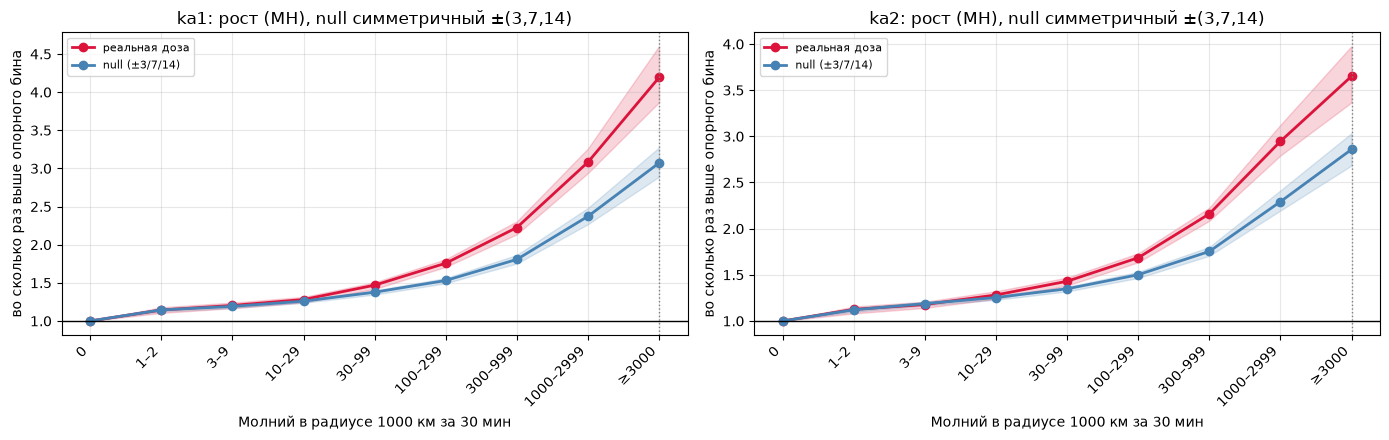

,КА,null,бин дозы,рост MH,рост null,сверх null,CI сверх null
0,ka1,null назад (основной блок),≥3000,4.192,3.271,1.282,1.20–1.36
1,ka1,null ±симметричный,≥3000,4.192,3.071,1.365,1.27–1.45
2,ka2,null назад (основной блок),≥3000,3.651,2.968,1.230,1.16–1.31
3,ka2,null ±симметричный,≥3000,3.651,2.859,1.277,1.21–1.36


Если «сверх null» с симметричными лагами близко к обычному (только назад) — трендовое смещение внутри периода несущественно. Если сильно ниже/выше — значит тренд активности гроз внутри периода оценки реально влиял на прежнюю оценку.
CPU times: user 5min 49s, sys: 2min 2s, total: 7min 51s
Wall time: 8min 12s


In [5]:
%%time
import traceback

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import wwlln_common as wc
import dose_pipeline as dp

accum_sym = None
try:
    wc.require_globals(globals(), ['df', 'df_pred', 'DOSE_SC', 'acc_days', 'DOSE_R_KM', 'DOSE_DT_MIN', 'GLAT', 'GLON', 'GDT_MIN', 'NULL_LAGS', 'NULL_SYMMETRIC', 'NULL_SEASON_SAFE', 'NIGHT_SZA_DEG', 'STRATA_SCHEME', 'DOSE_EDGES', 'DOSE_LABELS', 'MIN_STRAT_EXP', 'MIN_REPORT_EXP', 'N_BOOT', 'REF_BIN'], hint='выполните ячейку 94583c9b (основной блок, загрузка) перед этой')
    accum_sym = dp.run_accumulation(
        df, df_pred, sc_list=DOSE_SC, acc_days=acc_days,
        dose_r_km=DOSE_R_KM, dose_dt_min=DOSE_DT_MIN,
        glat=GLAT, glon=GLON, gdt_min=GDT_MIN,
        null_lags=NULL_LAGS, null_symmetric=True, null_season_safe=NULL_SEASON_SAFE,
        do_energy=False, night_sza_deg=NIGHT_SZA_DEG, strata_scheme=STRATA_SCHEME,
        dose_edges=DOSE_EDGES,
    )
except Exception:
    print('!!! ОШИБКА в accum_sym — остальные ячейки ноутбука продолжат выполняться:')
    traceback.print_exc()

RES_SYM = {}
if accum_sym is not None:
    x_sym = np.arange(accum_sym['n_dose'])
    fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5), squeeze=False)
    for si, sc in enumerate(DOSE_SC):
        r = dp.analyze(accum_sym, sc=si, n_boot=N_BOOT, ref_bin=REF_BIN, min_strat_exp=MIN_STRAT_EXP)
        RES_SYM[sc] = r
        rb = dp.report_bin(r, min_exp=MIN_REPORT_EXP, min_strata=5, ref_bin=REF_BIN)
        ax = axes[0, si]
        ax.plot(x_sym, r['rr_t'], 'o-', color='crimson', lw=2, label='реальная доза')
        ax.fill_between(x_sym, r['ci_t'][0], r['ci_t'][1], color='crimson', alpha=0.18)
        ax.plot(x_sym, r['rr_n'], 'o-', color='steelblue', lw=2, label='null (±3/7/14)')
        ax.fill_between(x_sym, r['ci_n'][0], r['ci_n'][1], color='steelblue', alpha=0.18)
        ax.axhline(1.0, color='k', lw=1)
        if rb is not None:
            ax.axvline(rb, color='gray', ls=':', lw=1)
        ax.set_xticks(x_sym)
        ax.set_xticklabels(DOSE_LABELS, rotation=45, ha='right')
        ax.set_xlabel(f'Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин')
        ax.set_ylabel('во сколько раз выше опорного бина')
        ax.set_title(f'{sc}: рост (MH), null симметричный ±(3,7,14)')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    rows = []
    for si, sc in enumerate(DOSE_SC):
        for label, res_dict in [('null назад (основной блок)', RES if 'RES' in globals() else {}),
                                ('null ±симметричный', RES_SYM)]:
            r = res_dict.get(sc)
            if r is None:
                rows.append({'КА': sc, 'null': label, 'бин дозы': 'нет данных'})
                continue
            b = dp.report_bin(r, min_exp=MIN_REPORT_EXP, min_strata=5, ref_bin=REF_BIN)
            if b is None:
                rows.append({'КА': sc, 'null': label, 'бин дозы': 'нет носителя'})
                continue
            rows.append({
                'КА': sc, 'null': label, 'бин дозы': DOSE_LABELS[b],
                'рост MH': r['rr_t'][b], 'рост null': r['rr_n'][b], 'сверх null': r['rrr'][b],
                'CI сверх null': f"{r['ci_rrr'][0,b]:.2f}–{r['ci_rrr'][1,b]:.2f}",
            })
    sym_summary = pd.DataFrame(rows)
    display(sym_summary.round(3))
    print('Если «сверх null» с симметричными лагами близко к обычному (только назад) — '
          'трендовое смещение внутри периода несущественно. Если сильно ниже/выше — '
          'значит тренд активности гроз внутри периода оценки реально влиял на прежнюю оценку.')
else:
    print('accum_sym не посчитан — см. traceback выше, эта ячейка пропущена.')


## 4.1. ka4, схема LST

ka1 и ka2 считаются по суткам, где есть оба аппарата. У ka4 таких суток в этом окне нет. В сохранённом прогоне 10 суток, 21–31 августа 2025, без 22 августа. Страты грубее: широта 30°, местное время 6 ч, порог носителя мягче. Блоков бутстрапа 10 против 255 у основного окна, интервал грубый. Смотреть направление, не точное число.


ka4: 10 суток предсказаний (20250821 … 20250831)
AE из кэша: /Users/user/Downloads/wwlln/cache/AE_20250101_20251231.parquet
ka4: 10 файлов из /Users/user/Downloads/wwlln/whistler_binary/ka4
Накопители: 0 МБ; сетки строим для 26 дней (схема страт='lst', лаги=(3, 7, 14) назад, сезонный фильтр=вкл)
  ... 20/26 дней
Готово. Экспозиция: 693,512 сэмплов, verdict=1: 160,755 (23.18%); экспозиция null: 2,080,536 (в среднем 3.00 лага/сутки использовано из 3 возможных)


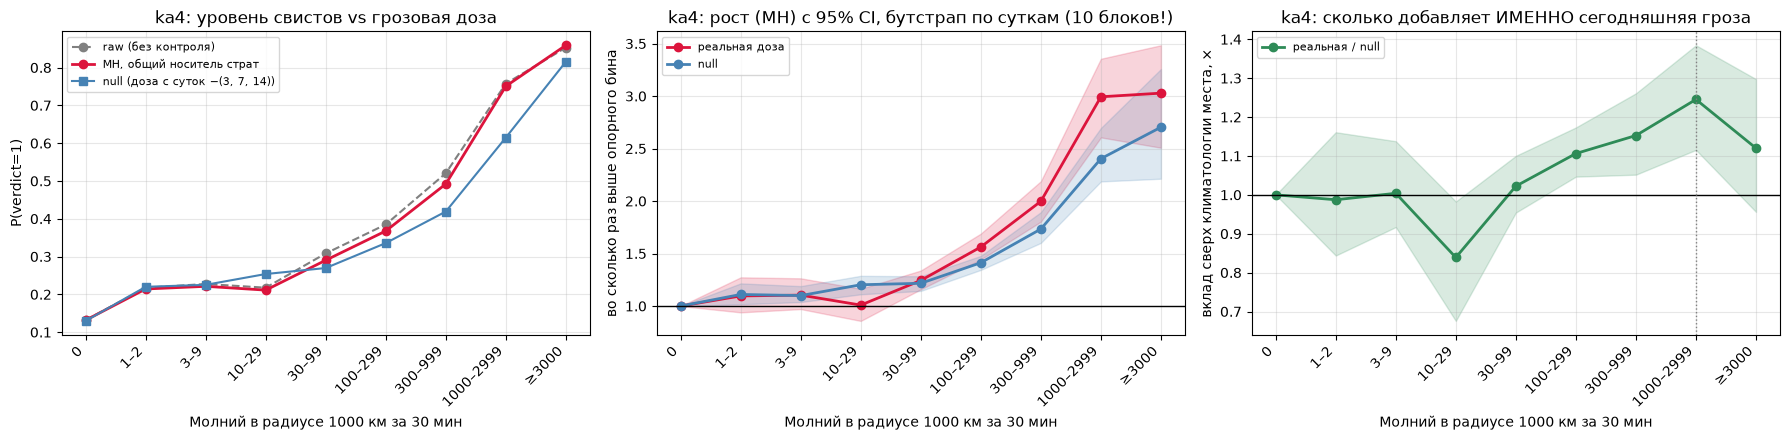

ka4: 10 суток оценки — CI ниже стоит читать с большой осторожностью (10 блоков бутстрапа против 255 в основном блоке)
  все: бин=1000–2999, экспозиция=14890, страт=6, рост MH=2.99 CI=[2.61,3.36], рост null=2.40, сверх null=1.25 CI=[1.12,1.38]
  ночь: бин=1000–2999, экспозиция=5437, страт=3, рост MH=2.01 CI=[1.70,2.38], рост null=1.79, сверх null=1.12 CI=[0.95,1.28]
  день: бин=1000–2999, экспозиция=9453, страт=3, рост MH=4.20 CI=[3.57,5.03], рост null=3.21, сверх null=1.31 CI=[1.00,1.68]
Для сравнения — направление (день > ночь по «сверх null») здесь то же, что и у ka1/ka2: разведочный сигнал не противоречит основному выводу.
CPU times: user 15.4 s, sys: 11.9 s, total: 27.3 s
Wall time: 22.1 s


In [6]:
%%time
import traceback

import numpy as np
import matplotlib.pyplot as plt

import wwlln_common as wc
import dose_pipeline as dp

KA4_SC = ('ka4',)
KA4_DAYS = wc.analysis_days(_paths_d['pred'], _paths_d['ae'], KA4_SC)
print(f'ka4: {len(KA4_DAYS)} суток предсказаний ({KA4_DAYS[0]} … {KA4_DAYS[-1]})')

KA4_MAX_LAG = max(NULL_LAGS)
_ka4_dc = wc.day_codes(KA4_DAYS)
KA4_AE_DAYS = [str(np.datetime64(int(c), 'D')).replace('-', '')
              for c in range(int(_ka4_dc.min()) - KA4_MAX_LAG - 1, int(_ka4_dc.max()) + 1)]

_cache = _paths_d['cache'] / 'AE_20250101_20251231.parquet'
df_ka4 = wc.load_ae(ae_dir=_paths_d['ae'], cache_path=_cache, days=KA4_AE_DAYS, verbose=True)
df_pred_ka4 = wc.load_predictions(_paths_d['pred'], sc_list=KA4_SC, days=KA4_DAYS, verbose=True)
ka4_acc_days = sorted(int(d) for d in _ka4_dc)

# грубее страты и мягче пороги, чем в основном блоке — иначе почти ничего не
# пройдёт общий носитель при всего 10 сутках данных
KA4_N_LATB, KA4_N_HOURB = 6, 4          # 30° по широте, 6ч по LST
KA4_MIN_STRAT_EXP, KA4_MIN_REPORT_EXP = 150, 1500

accum_ka4 = None
try:
    wc.require_globals(globals(), ['_paths_d', 'NULL_LAGS', 'DOSE_R_KM', 'DOSE_DT_MIN', 'GLAT', 'GLON', 'GDT_MIN', 'NIGHT_SZA_DEG', 'DOSE_LABELS'], hint='выполните ячейку 94583c9b (основной блок, загрузка) перед этой')
    accum_ka4 = dp.run_accumulation(
        df_ka4, df_pred_ka4, sc_list=KA4_SC, acc_days=ka4_acc_days,
        dose_r_km=DOSE_R_KM, dose_dt_min=DOSE_DT_MIN, glat=GLAT, glon=GLON, gdt_min=GDT_MIN,
        null_lags=NULL_LAGS, null_symmetric=False, null_season_safe=True,
        do_energy=False,      # выборка мала — энергетический срез был бы совсем шумным
        night_sza_deg=NIGHT_SZA_DEG, strata_scheme='lst',
        n_latb=KA4_N_LATB, n_hourb=KA4_N_HOURB,
    )
except Exception:
    print('!!! ОШИБКА в accum_ka4 — остальные ячейки ноутбука продолжат выполняться:')
    traceback.print_exc()

RES_KA4 = {}
if accum_ka4 is not None:
    x_ka4 = np.arange(accum_ka4['n_dose'])
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    r = dp.analyze(accum_ka4, sc=0, n_boot=200, ref_bin=0, min_strat_exp=KA4_MIN_STRAT_EXP)
    RES_KA4['все'] = r
    rb = dp.report_bin(r, min_exp=KA4_MIN_REPORT_EXP, min_strata=3, ref_bin=0)

    axes[0].plot(x_ka4, r['raw'], 'o--', color='gray', lw=1.5, label='raw (без контроля)')
    axes[0].plot(x_ka4, r['pk_t'], 'o-', color='crimson', lw=2, label='MH, общий носитель страт')
    axes[0].plot(x_ka4, r['pk_n'], 's-', color='steelblue', label=f'null (доза с суток −{NULL_LAGS})')
    axes[0].set_ylabel('P(verdict=1)')
    axes[0].set_title('ka4: уровень свистов vs грозовая доза')

    axes[1].plot(x_ka4, r['rr_t'], 'o-', color='crimson', lw=2, label='реальная доза')
    axes[1].fill_between(x_ka4, r['ci_t'][0], r['ci_t'][1], color='crimson', alpha=0.18)
    axes[1].plot(x_ka4, r['rr_n'], 'o-', color='steelblue', lw=2, label='null')
    axes[1].fill_between(x_ka4, r['ci_n'][0], r['ci_n'][1], color='steelblue', alpha=0.18)
    axes[1].axhline(1.0, color='k', lw=1)
    axes[1].set_ylabel('во сколько раз выше опорного бина')
    axes[1].set_title('ka4: рост (MH) с 95% CI, бутстрап по суткам (10 блоков!)')

    axes[2].plot(x_ka4, r['rrr'], 'o-', color='seagreen', lw=2, label='реальная / null')
    axes[2].fill_between(x_ka4, r['ci_rrr'][0], r['ci_rrr'][1], color='seagreen', alpha=0.18)
    axes[2].axhline(1.0, color='k', lw=1)
    if rb is not None:
        axes[2].axvline(rb, color='gray', ls=':', lw=1)
    axes[2].set_ylabel('вклад сверх климатологии места, ×')
    axes[2].set_title('ka4: сколько добавляет ИМЕННО сегодняшняя гроза')

    for ax in axes:
        ax.set_xticks(x_ka4)
        ax.set_xticklabels(DOSE_LABELS, rotation=45, ha='right')
        ax.set_xlabel(f'Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    print(f'ka4: {len(ka4_acc_days)} суток оценки — CI ниже стоит читать с большой осторожностью '
          f'(10 блоков бутстрапа против 255 в основном блоке)')
    for night, lab in [(None, 'все'), (1, 'ночь'), (0, 'день')]:
        r = dp.analyze(accum_ka4, sc=0, night=night, n_boot=200, ref_bin=0,
                       min_strat_exp=KA4_MIN_STRAT_EXP)
        RES_KA4[lab] = r
        b = dp.report_bin(r, min_exp=KA4_MIN_REPORT_EXP, min_strata=3, ref_bin=0)
        if b is None:
            print(f'  {lab}: нет бина с достаточным носителем')
            continue
        print(f'  {lab}: бин={DOSE_LABELS[b]}, экспозиция={r["expo"][b]:.0f}, страт={r["nst"][b]}, '
              f'рост MH={r["rr_t"][b]:.2f} CI=[{r["ci_t"][0,b]:.2f},{r["ci_t"][1,b]:.2f}], '
              f'рост null={r["rr_n"][b]:.2f}, сверх null={r["rrr"][b]:.2f} '
              f'CI=[{r["ci_rrr"][0,b]:.2f},{r["ci_rrr"][1,b]:.2f}]')
    print('Для сравнения — направление (день > ночь по «сверх null») здесь то же, что и у ka1/ka2: '
          'разведочный сигнал не противоречит основному выводу.')
else:
    print('accum_ka4 не посчитан — см. traceback выше, эта ячейка пропущена.')


## 4.4. Долгота вместо местного времени

Местное время разрешает суточный ход. Долгота — суша и океан, Южно-Атлантическая аномалия, регион внутри одного широтного пояса — входит в него через местный час. Ночь уже отделяет день и ночь по зенитному углу Солнца. Ось местного времени заменена долготой 45°: широта 15° × долгота 45° × сезон × ночь. Число комбинаций того же порядка, 12 × 8 × 4 × 2 = 768.

Доза по-прежнему вокруг точки под спутником, радиус 1000 км, окно 30 мин. Симметричные лаги null в этом блоке включены. Сезонный фильтр лага тот же, что в первом расчёте. Носитель, энергия, диагностика, день и ночь, перебор радиуса и геометрия ниже опираются на `accum_lon` и `RES_LON` из этой ячейки.


Накопители: 81 МБ; сетки строим для 314 дней (схема страт='lon', лаги=(3, 7, 14)±, сезонный фильтр=вкл)
  ... 20/314 дней
  ... 40/314 дней
  ... 60/314 дней
  ... 80/314 дней
  ... 100/314 дней
  ... 120/314 дней
  ... 140/314 дней
  ... 160/314 дней
  ... 180/314 дней
  ... 200/314 дней
  ... 220/314 дней
  ... 240/314 дней
  ... 260/314 дней
  ... 280/314 дней
  ... 300/314 дней
Готово. Экспозиция: 41,985,036 сэмплов, verdict=1: 3,816,529 (9.09%); экспозиция null: 232,113,950 (в среднем 5.53 лага/сутки использовано из 6 возможных)


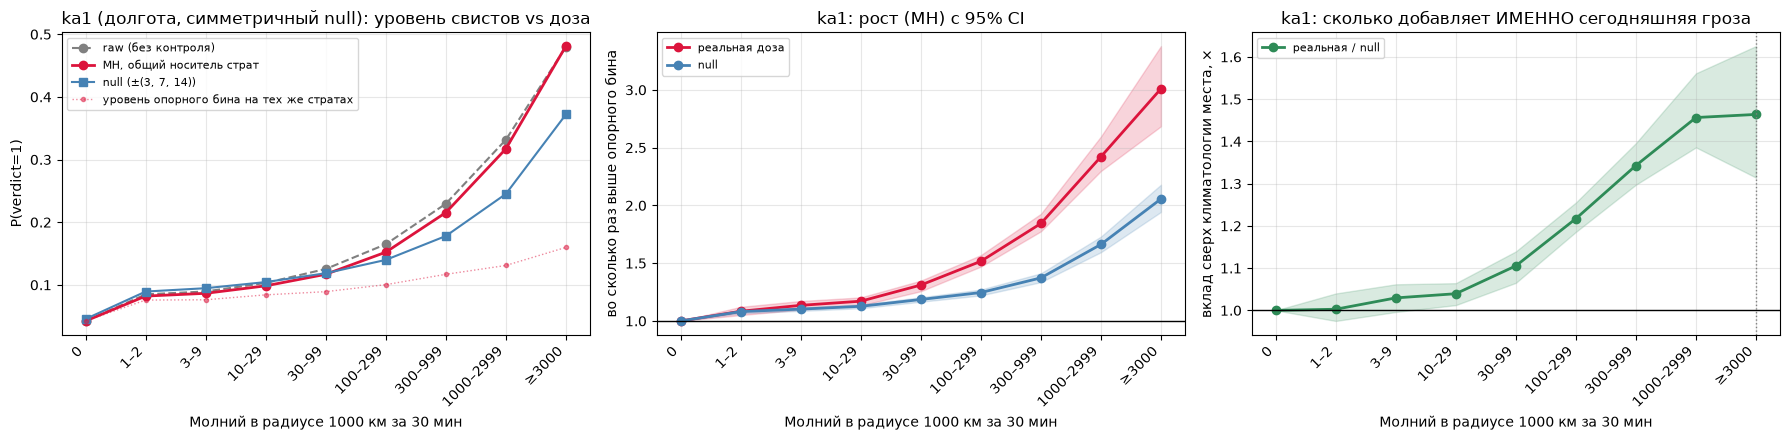

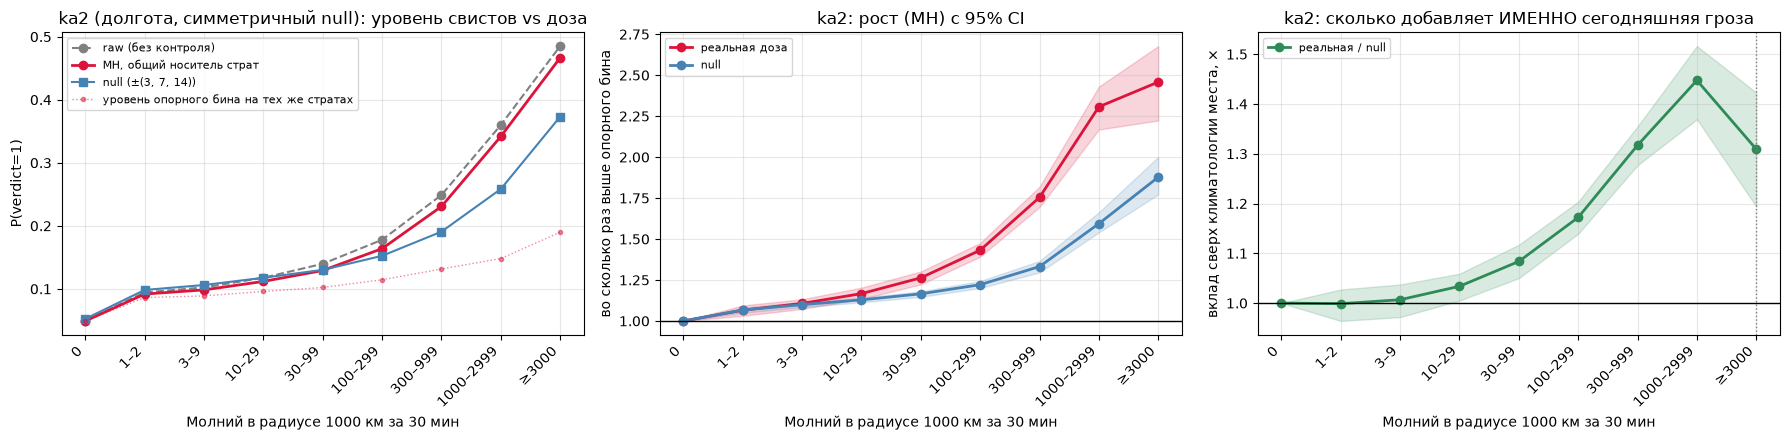

,КА,схема,бин дозы,рост MH,рост null,сверх null,CI сверх null
0,ka1,LST (основной блок),нет данных,NaN,NaN,NaN,NaN
1,ka1,долгота + симметричный null,≥3000,3.010,2.056,1.464,1.31–1.63
2,ka2,LST (основной блок),нет данных,NaN,NaN,NaN,NaN
3,ka2,долгота + симметричный null,≥3000,2.458,1.878,1.309,1.19–1.42


Если «сверх null» у схемы «долгота+симметричный null» близко к LST-схеме — вывод не зависит ни от способа контроля географии, ни от направления null-лагов. Если сильно разъезжается — стоит разбираться, какой из двух факторов (схема страт или лаги) внёс разницу.
CPU times: user 5min 52s, sys: 2min 21s, total: 8min 14s
Wall time: 8min 44s


In [3]:
%%time
import traceback

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import wwlln_common as wc
import dose_pipeline as dp

accum_lon = None
try:
    wc.require_globals(globals(), ['df', 'df_pred', 'DOSE_SC', 'acc_days', 'DOSE_R_KM', 'DOSE_DT_MIN', 'GLAT', 'GLON', 'GDT_MIN', 'NULL_LAGS', 'NULL_SYMMETRIC', 'NULL_SEASON_SAFE', 'NIGHT_SZA_DEG', 'STRATA_SCHEME', 'DOSE_EDGES', 'DOSE_LABELS', 'MIN_STRAT_EXP', 'MIN_REPORT_EXP', 'N_BOOT', 'REF_BIN'], hint='выполните ячейку 94583c9b (основной блок, загрузка) перед этой')
    accum_lon = dp.run_accumulation(
        df, df_pred, sc_list=DOSE_SC, acc_days=acc_days,
        dose_r_km=DOSE_R_KM, dose_dt_min=DOSE_DT_MIN,
        glat=GLAT, glon=GLON, gdt_min=GDT_MIN,
        null_lags=NULL_LAGS, null_symmetric=True, null_season_safe=NULL_SEASON_SAFE,
        do_energy=False, night_sza_deg=NIGHT_SZA_DEG, strata_scheme='lon', n_lonb=8,
        dose_edges=DOSE_EDGES,
    )
except Exception:
    print('!!! ОШИБКА в accum_lon — остальные ячейки ноутбука продолжат выполняться:')
    traceback.print_exc()

RES_LON = {}
if accum_lon is not None:
    x_lon = np.arange(accum_lon['n_dose'])
    for si, sc in enumerate(DOSE_SC):
        RES_LON[sc] = dp.analyze(accum_lon, sc=si, n_boot=N_BOOT, ref_bin=REF_BIN,
                                 min_strat_exp=MIN_STRAT_EXP)
        r = RES_LON[sc]
        rb = dp.report_bin(r, min_exp=MIN_REPORT_EXP, min_strata=5, ref_bin=REF_BIN)

        fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
        axes[0].plot(x_lon, r['raw'], 'o--', color='gray', lw=1.5, label='raw (без контроля)')
        axes[0].plot(x_lon, r['pk_t'], 'o-', color='crimson', lw=2, label='MH, общий носитель страт')
        axes[0].plot(x_lon, r['pk_n'], 's-', color='steelblue', label=f'null (±{NULL_LAGS})')
        axes[0].plot(x_lon, r['p0_t'], '.:', color='crimson', alpha=0.5, lw=1,
                    label='уровень опорного бина на тех же стратах')
        axes[0].set_ylabel('P(verdict=1)')
        axes[0].set_title(f'{sc} (долгота, симметричный null): уровень свистов vs доза')

        for key, ci, color, lab in [('rr_t', 'ci_t', 'crimson', 'реальная доза'),
                                    ('rr_n', 'ci_n', 'steelblue', 'null')]:
            axes[1].plot(x_lon, r[key], 'o-', color=color, lw=2, label=lab)
            axes[1].fill_between(x_lon, r[ci][0], r[ci][1], color=color, alpha=0.18)
        axes[1].axhline(1.0, color='k', lw=1)
        axes[1].set_ylabel('во сколько раз выше опорного бина')
        axes[1].set_title(f'{sc}: рост (MH) с 95% CI')

        axes[2].plot(x_lon, r['rrr'], 'o-', color='seagreen', lw=2, label='реальная / null')
        axes[2].fill_between(x_lon, r['ci_rrr'][0], r['ci_rrr'][1], color='seagreen', alpha=0.18)
        axes[2].axhline(1.0, color='k', lw=1)
        if rb is not None:
            axes[2].axvline(rb, color='gray', ls=':', lw=1)
        axes[2].set_ylabel('вклад сверх климатологии места, ×')
        axes[2].set_title(f'{sc}: сколько добавляет ИМЕННО сегодняшняя гроза')

        for ax in axes:
            ax.set_xticks(x_lon)
            ax.set_xticklabels(DOSE_LABELS, rotation=45, ha='right')
            ax.set_xlabel(f'Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин')
            ax.grid(alpha=0.3)
            ax.legend(fontsize=8)
        fig.tight_layout()
        plt.show()
        plt.close(fig)

    # --- сводка: satellite/LST (основной блок) vs долгота+симметричный null ---
    rows = []
    for si, sc in enumerate(DOSE_SC):
        for label, res_dict in [('LST (основной блок)', RES if 'RES' in globals() else {}),
                                ('долгота + симметричный null', RES_LON)]:
            r = res_dict.get(sc)
            if r is None:
                rows.append({'КА': sc, 'схема': label, 'бин дозы': 'нет данных'})
                continue
            b = dp.report_bin(r, min_exp=MIN_REPORT_EXP, min_strata=5, ref_bin=REF_BIN)
            if b is None:
                rows.append({'КА': sc, 'схема': label, 'бин дозы': 'нет носителя'})
                continue
            rows.append({
                'КА': sc, 'схема': label, 'бин дозы': DOSE_LABELS[b],
                'рост MH': r['rr_t'][b], 'рост null': r['rr_n'][b], 'сверх null': r['rrr'][b],
                'CI сверх null': f"{r['ci_rrr'][0,b]:.2f}–{r['ci_rrr'][1,b]:.2f}",
            })
    lon_vs_lst = pd.DataFrame(rows)
    display(lon_vs_lst.round(3))
    print('Если «сверх null» у схемы «долгота+симметричный null» близко к LST-схеме — вывод не '
          'зависит ни от способа контроля географии, ни от направления null-лагов. Если сильно '
          'разъезжается — стоит разбираться, какой из двух факторов (схема страт или лаги) внёс разницу.')
else:
    print('accum_lon не посчитан — см. traceback выше, эта ячейка пропущена.')


### Носитель и экспозиция по бинам дозы

Сколько страт прошло порог общего носителя и сколько секунд за этим стоит в каждом бине дозы. Считается по готовому `RES_LON`, нового прохода по суткам нет. По графику видно, какие точки кривой стоят на многих стратах. Разложение веса по широте, долготе, сезону и ночи — в диагностике ниже.


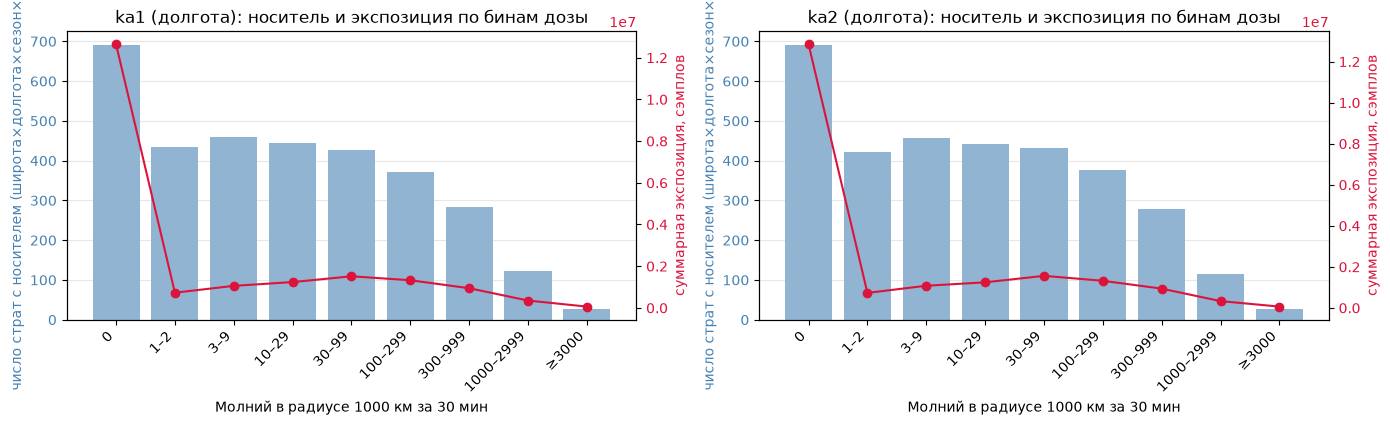

In [4]:
import numpy as np
import matplotlib.pyplot as plt

_deps = ['RES_LON', 'DOSE_SC', 'DOSE_LABELS', 'DOSE_R_KM', 'DOSE_DT_MIN']
_missing = [n for n in _deps if n not in globals()]
if _missing:
    print(f'Пропущено: не определено {_missing}. Выполните расчёт §4.4 «Долгота вместо местного времени» перед этой.')
else:
    x = np.arange(len(DOSE_LABELS))
    fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5), squeeze=False)
    for si, sc in enumerate(DOSE_SC):
        r = RES_LON.get(sc)
        if r is None:
            continue
        ax = axes[0, si]
        ax.bar(x, r['nst'], color='steelblue', alpha=0.6, label='страт с носителем')
        ax.set_ylabel('число страт с носителем (широта×долгота×сезон×ночь)', color='steelblue')
        ax.tick_params(axis='y', labelcolor='steelblue')
        ax2 = ax.twinx()
        ax2.plot(x, r['expo'], 'o-', color='crimson', label='суммарная экспозиция')
        ax2.set_ylabel('суммарная экспозиция, сэмплов', color='crimson')
        ax2.tick_params(axis='y', labelcolor='crimson')
        ax.set_xticks(x)
        ax.set_xticklabels(DOSE_LABELS, rotation=45, ha='right')
        ax.set_xlabel(f'Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин')
        ax.set_title(f'{sc} (долгота): носитель и экспозиция по бинам дозы')
        ax.grid(alpha=0.3, axis='y')
    fig.tight_layout()
    plt.show()
    plt.close(fig)


### Средняя энергия при фиксированной дозе — схема «долгота»

Тот же вопрос, что на схеме LST: при одном и том же числе молний меняется ли доля свистов, если эти разряды в среднем мощнее. Страты, радиус, окно и симметричный null — как в блоке долготы. В `accum_lon` энергия не копилась, поэтому здесь отдельное накопление.

Нулевой модели для энергии нет. В оценку входят бин дозы и страты. Сегменты энергии: <2 кДж, 2–6 кДж, ≥6 кДж.


Накопители: 161 МБ; сетки строим для 314 дней (схема страт='lon', лаги=(3, 7, 14)±, сезонный фильтр=вкл)
  ... 20/314 дней
  ... 40/314 дней
  ... 60/314 дней
  ... 80/314 дней
  ... 100/314 дней
  ... 120/314 дней
  ... 140/314 дней
  ... 160/314 дней
  ... 180/314 дней
  ... 200/314 дней
  ... 220/314 дней
  ... 240/314 дней
  ... 260/314 дней
  ... 280/314 дней
  ... 300/314 дней
Готово. Экспозиция: 41,985,036 сэмплов, verdict=1: 3,816,529 (9.09%); экспозиция null: 232,113,950 (в среднем 5.53 лага/сутки использовано из 6 возможных)


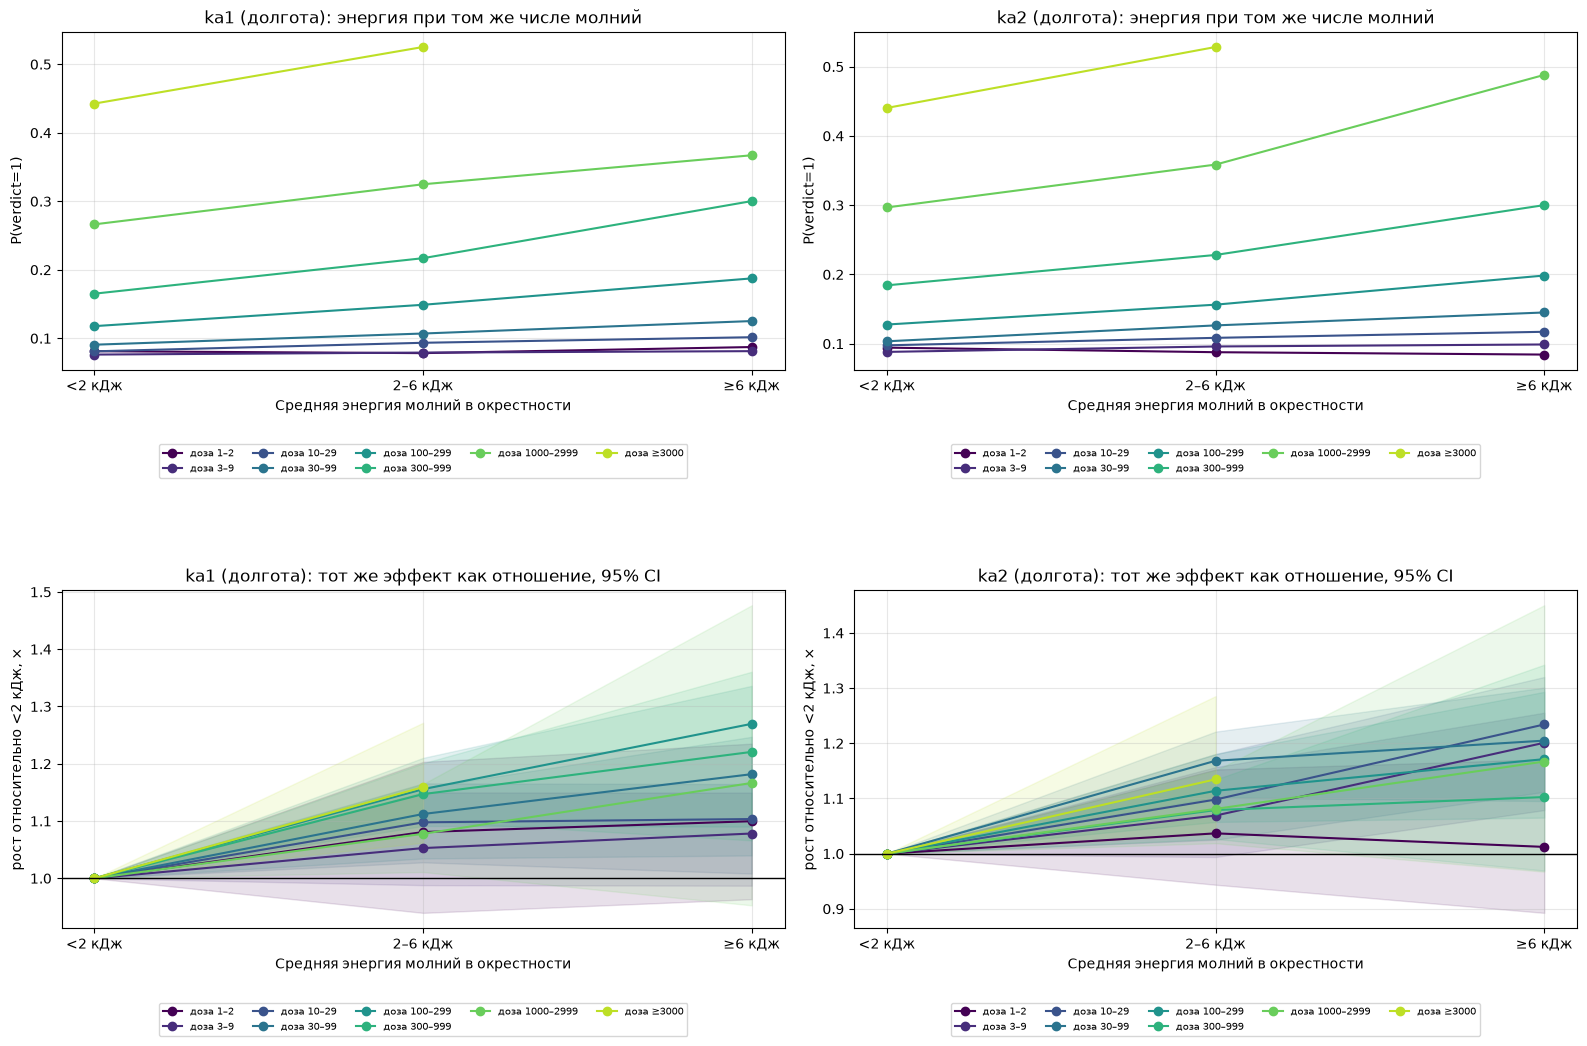

CPU times: user 6min 45s, sys: 2min 48s, total: 9min 33s
Wall time: 10min 19s


In [3]:
%%time
import traceback
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import wwlln_common as wc
import dose_pipeline as dp

_deps = ['df', 'df_pred', 'DOSE_SC', 'acc_days', 'DOSE_R_KM', 'DOSE_DT_MIN', 'GLAT', 'GLON',
         'GDT_MIN', 'NULL_LAGS', 'NULL_SEASON_SAFE', 'NIGHT_SZA_DEG', 'DOSE_EDGES', 'DOSE_LABELS',
         'MIN_STRAT_EXP', 'N_BOOT', 'E_EDGES', 'E_LABELS']
_missing = [n for n in _deps if n not in globals()]
if _missing:
    print(f'Пропущено: не определено {_missing}. Выполните ячейку загрузки в начале ноутбука перед этой.')
else:
    accum_lon_energy = None
    try:
        accum_lon_energy = dp.run_accumulation(
            df, df_pred, sc_list=DOSE_SC, acc_days=acc_days,
            dose_r_km=DOSE_R_KM, dose_dt_min=DOSE_DT_MIN,
            glat=GLAT, glon=GLON, gdt_min=GDT_MIN,
            null_lags=NULL_LAGS, null_symmetric=True, null_season_safe=NULL_SEASON_SAFE,
            do_energy=True, night_sza_deg=NIGHT_SZA_DEG, strata_scheme='lon', n_lonb=8,
            dose_edges=DOSE_EDGES, e_edges=E_EDGES,
        )
    except Exception:
        print('!!! ОШИБКА в accum_lon_energy — остальные ячейки ноутбука продолжат выполняться:')
        traceback.print_exc()

    if accum_lon_energy is not None:
        def analyze_energy_lon(accum, si, db, ref_bin=0, n_boot=N_BOOT, seed=0,
                               min_strat_exp=MIN_STRAT_EXP):
            """Эффект средней энергии молний при ФИКСИРОВАННОМ их числе (бин дозы db),
            схема «долгота». Как и в LST-варианте — контроль только страты + фиксация
            дозы, нулевой модели для энергии нет (см. markdown выше)."""
            Et_full = accum['exp_en_d'][:, si, ..., db, :]
            Pt_full = accum['pos_en_d'][:, si, ..., db, :]
            nd = Et_full.shape[0]
            E2 = Et_full.reshape(nd, -1, Et_full.shape[-1])
            P2 = Pt_full.reshape(nd, -1, Pt_full.shape[-1])
            rr, p_ref, p_k, nst, expo = dp.mh(E2.sum(axis=0), P2.sum(axis=0), ref=ref_bin,
                                              min_exp=min_strat_exp)
            rng = np.random.default_rng(seed)
            bs = np.full((n_boot, E2.shape[2]), np.nan)
            for b in range(n_boot):
                c = np.bincount(rng.integers(0, nd, nd), minlength=nd).astype(np.float32)
                bs[b] = dp.mh(np.tensordot(c, E2, axes=1), np.tensordot(c, P2, axes=1),
                              ref=ref_bin, min_exp=min_strat_exp)[0]
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', RuntimeWarning)
                ci = np.nanpercentile(bs, [2.5, 97.5], axis=0)
            return rr, ci, p_k, nst, expo

        n_dose_e = accum_lon_energy['n_dose']
        show_bins = [i for i in range(1, n_dose_e)
                    if accum_lon_energy['exp_en_d'][..., i, :].sum() > 50 * MIN_STRAT_EXP]
        if show_bins:
            ncol = min(len(show_bins), 5)
            fig, axes = plt.subplots(2, len(DOSE_SC), figsize=(8 * len(DOSE_SC), 11.0), squeeze=False)
            for si, sc in enumerate(DOSE_SC):
                ax_a, ax_r = axes[0, si], axes[1, si]
                cmap = plt.cm.viridis(np.linspace(0, 0.9, len(show_bins)))
                for ci_i, db in enumerate(show_bins):
                    rr, ci95, p_k, nst, _ = analyze_energy_lon(accum_lon_energy, si, db)
                    x = np.arange(accum_lon_energy['n_eb'])
                    ax_a.plot(x, p_k, 'o-', color=cmap[ci_i], label=f'доза {DOSE_LABELS[db]}')
                    ax_r.plot(x, rr, 'o-', color=cmap[ci_i], label=f'доза {DOSE_LABELS[db]}')
                    ax_r.fill_between(x, ci95[0], ci95[1], color=cmap[ci_i], alpha=0.12)
                ax_r.axhline(1.0, color='k', lw=1)
                ax_a.set_ylabel('P(verdict=1)')
                ax_r.set_ylabel('рост относительно <2 кДж, ×')
                ax_a.set_title(f'{sc} (долгота): энергия при том же числе молний')
                ax_r.set_title(f'{sc} (долгота): тот же эффект как отношение, 95% CI')
                for ax in (ax_a, ax_r):
                    ax.set_xticks(np.arange(accum_lon_energy['n_eb']))
                    ax.set_xticklabels(E_LABELS)
                    ax.set_xlabel('Средняя энергия молний в окрестности')
                    ax.grid(alpha=0.3)
                    ax.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.22),
                              ncol=ncol, borderaxespad=0.)
            fig.tight_layout(rect=[0, 0.03, 1, 1])
            fig.subplots_adjust(hspace=0.65)
            plt.show()
            plt.close(fig)
        else:
            print('Нет ни одного бина дозы с достаточной экспозицией по энергии — график не построен.')
    else:
        print('accum_lon_energy не посчитан — см. traceback выше, эта ячейка пропущена.')


### Интервалы для средней энергии

Те же кривые таблицей: рост и 95% интервал по каждому бину дозы и сегменту энергии. Новый проход по данным не нужен. Берутся `accum_lon_energy` и `analyze_energy_lon` из ячейки выше.


In [7]:
import numpy as np
import pandas as pd

_deps = ['accum_lon_energy', 'analyze_energy_lon', 'show_bins', 'DOSE_SC', 'DOSE_LABELS', 'E_LABELS']
_missing = [n for n in _deps if n not in globals()]
if _missing:
    print(f'Пропущено: не определено {_missing}. Выполните предыдущую ячейку (энергия, долгота) перед этой.')
elif accum_lon_energy is None or not show_bins:
    print('accum_lon_energy не посчитан или нет бинов с носителем \u2014 таблицу построить не из чего.')
else:
    rows = []
    for si, sc in enumerate(DOSE_SC):
        for db in show_bins:
            rr, ci95, p_k, nst, expo = analyze_energy_lon(accum_lon_energy, si, db)
            for eb in range(1, accum_lon_energy['n_eb']):
                if not np.isfinite(rr[eb]):
                    continue
                rows.append({
                    'КА': sc,
                    'бин дозы': DOSE_LABELS[db],
                    'энергия': f'{E_LABELS[eb]} vs {E_LABELS[0]}',
                    'рост': rr[eb],
                    'CI низ': ci95[0, eb],
                    'CI верх': ci95[1, eb],
                    'страт': int(nst[eb]),
                    'CI накрывает 1?': 'да' if ci95[0, eb] <= 1.0 <= ci95[1, eb] else 'нет',
                })
    energy_lon_ci_table = pd.DataFrame(rows)
    display(energy_lon_ci_table.round(3))
    n_total = len(energy_lon_ci_table)
    n_covering = (energy_lon_ci_table['CI накрывает 1?'] == 'да').sum()
    print(f'CI накрывает 1.0 в {n_covering} из {n_total} строк ({100*n_covering/max(n_total,1):.0f}%).')


,КА,бин дозы,энергия,рост,CI низ,CI верх,страт,CI накрывает 1?
0,ka1,1–2,2–6 кДж vs <2 кДж,1.081,0.940,1.203,112,да
1,ka1,1–2,≥6 кДж vs <2 кДж,1.100,0.964,1.235,97,да
2,ka1,3–9,2–6 кДж vs <2 кДж,1.053,0.988,1.150,180,да
3,ka1,3–9,≥6 кДж vs <2 кДж,1.078,0.987,1.150,144,да
4,ka1,10–29,2–6 кДж vs <2 кДж,1.098,1.028,1.166,189,нет
5,ka1,10–29,≥6 кДж vs <2 кДж,1.103,1.008,1.164,136,нет
6,ka1,30–99,2–6 кДж vs <2 кДж,1.112,1.035,1.158,198,нет
7,ka1,30–99,≥6 кДж vs <2 кДж,1.182,1.040,1.247,119,нет
8,ka1,100–299,2–6 кДж vs <2 кДж,1.156,1.091,1.210,166,нет
9,ka1,100–299,≥6 кДж vs <2 кДж,1.270,1.090,1.336,61,нет


CI накрывает 1.0 в 10 из 30 строк (33%).


### Какие дозы лежат внутри сегмента энергии

График выше — эффект энергии при фиксированной дозе. Здесь обратный срез: для каждого сегмента средней энергии (<2 кДж, 2–6 кДж, ≥6 кДж) доля экспозиции по бинам дозы. Сумма по бинам дозы внутри сегмента равна 100%. Тот же накопитель `accum_lon_energy`.


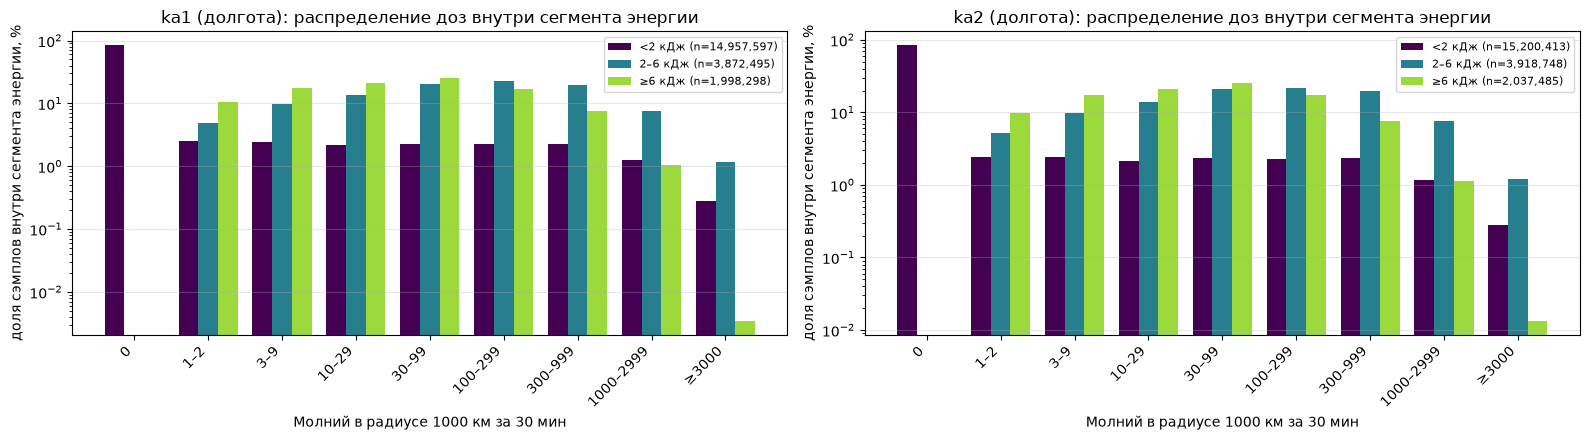

,КА,бин дозы,"<2 кДж, %","2–6 кДж, %","≥6 кДж, %"
0,ka1,0,84.58,0.00,0.00
1,ka1,1–2,2.48,4.94,10.42
2,ka1,3–9,2.44,9.81,17.57
3,ka1,10–29,2.20,13.83,21.35
4,ka1,30–99,2.29,20.27,25.14
5,ka1,100–299,2.24,22.55,16.76
6,ka1,300–999,2.25,19.79,7.70
7,ka1,1000–2999,1.25,7.65,1.06
8,ka1,≥3000,0.27,1.15,0.00
9,ka2,0,84.54,0.00,0.00


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_deps = ['accum_lon_energy', 'DOSE_SC', 'DOSE_LABELS', 'E_LABELS', 'DOSE_R_KM', 'DOSE_DT_MIN']
_missing = [n for n in _deps if n not in globals()]
if _missing:
    print(f'Пропущено: не определено {_missing}. Выполните §4.4 (энергия, долгота) перед этой.')
elif accum_lon_energy is None:
    print('accum_lon_energy не посчитан (см. traceback в §4.4) — эта ячейка пропущена.')
else:
    n_dose_e = accum_lon_energy['n_dose']
    n_eb = accum_lon_energy['n_eb']
    x = np.arange(n_dose_e)
    width = 0.8 / n_eb
    colors_e = plt.cm.viridis(np.linspace(0, 0.85, n_eb))

    fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(8 * len(DOSE_SC), 4.5), squeeze=False)
    dose_dist_rows = []
    for si, sc in enumerate(DOSE_SC):
        # exp_en_d: (сутки, КА, широта, долгота, сезон, ночь, доза, энергия) —
        # берём КА si, сворачиваем всё, кроме дозы и энергии
        exp_e = accum_lon_energy['exp_en_d'][:, si].sum(axis=(0, 1, 2, 3, 4)).astype(np.float64)
        totals = exp_e.sum(axis=0)
        pct = np.divide(exp_e, totals, out=np.zeros_like(exp_e), where=totals > 0) * 100

        ax = axes[0, si]
        for eb in range(n_eb):
            ax.bar(x + (eb - (n_eb - 1) / 2) * width, pct[:, eb], width,
                   color=colors_e[eb], label=f'{E_LABELS[eb]} (n={totals[eb]:,.0f})')
        ax.set_xticks(x)
        ax.set_xticklabels(DOSE_LABELS, rotation=45, ha='right')
        ax.set_ylabel('доля сэмплов внутри сегмента энергии, %')
        ax.set_xlabel(f'Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин')
        ax.set_title(f'{sc} (долгота): распределение доз внутри сегмента энергии')
        ax.set_yscale('log')
        ax.grid(alpha=0.3, axis='y')
        ax.legend(fontsize=8)

        for db in range(n_dose_e):
            row = {'КА': sc, 'бин дозы': DOSE_LABELS[db]}
            for eb in range(n_eb):
                row[f'{E_LABELS[eb]}, %'] = pct[db, eb]
            dose_dist_rows.append(row)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    dose_energy_dist_table = pd.DataFrame(dose_dist_rows)
    display(dose_energy_dist_table.round(2))

### Медиана энергии при фиксированной дозе

Среднее тянут редкие очень сильные разряды, поэтому тот же вопрос пересчитан по медиане энергии в окне 1000 км / 30 мин. Медиана не складывается по ячейкам сетки, обычные суммы накопления для неё не годятся. В `dp.run_median_energy_lon` на каждую ячейку копится гистограмма по тонким энергобинам, медиана внутри окна находится по кумулятивной гистограмме.

На гладких распределениях (экспоненциальное, равномерное, логнормальное) приближённая медиана попадает не в тот сегмент <2 / 2–6 / ≥6 кДж примерно в 0.2–0.3% случаев. На двумодальном примере, где точная медиана лежит в пустом промежутке между двумя кластерами, после поправки на пустой бин расхождение около 2%. Нулевой модели для энергии нет, как и для среднего. Форма накопителя совместима с `analyze_energy_lon`.


Гистограмма энергии (медиана): 16 тонких бинов (0…4000, +overflow), ~570 МБ на кэш из 2 суток; сетки строим для 286 дней (схема страт='lon')
  ... 20/286 дней
  ... 40/286 дней
  ... 60/286 дней
  ... 80/286 дней
  ... 100/286 дней
  ... 120/286 дней
  ... 140/286 дней
  ... 160/286 дней
  ... 180/286 дней
  ... 200/286 дней
  ... 220/286 дней
  ... 240/286 дней
  ... 260/286 дней
  ... 280/286 дней
Готово. Экспозиция: 41,985,036 сэмплов, verdict=1: 3,816,529 (9.09%)


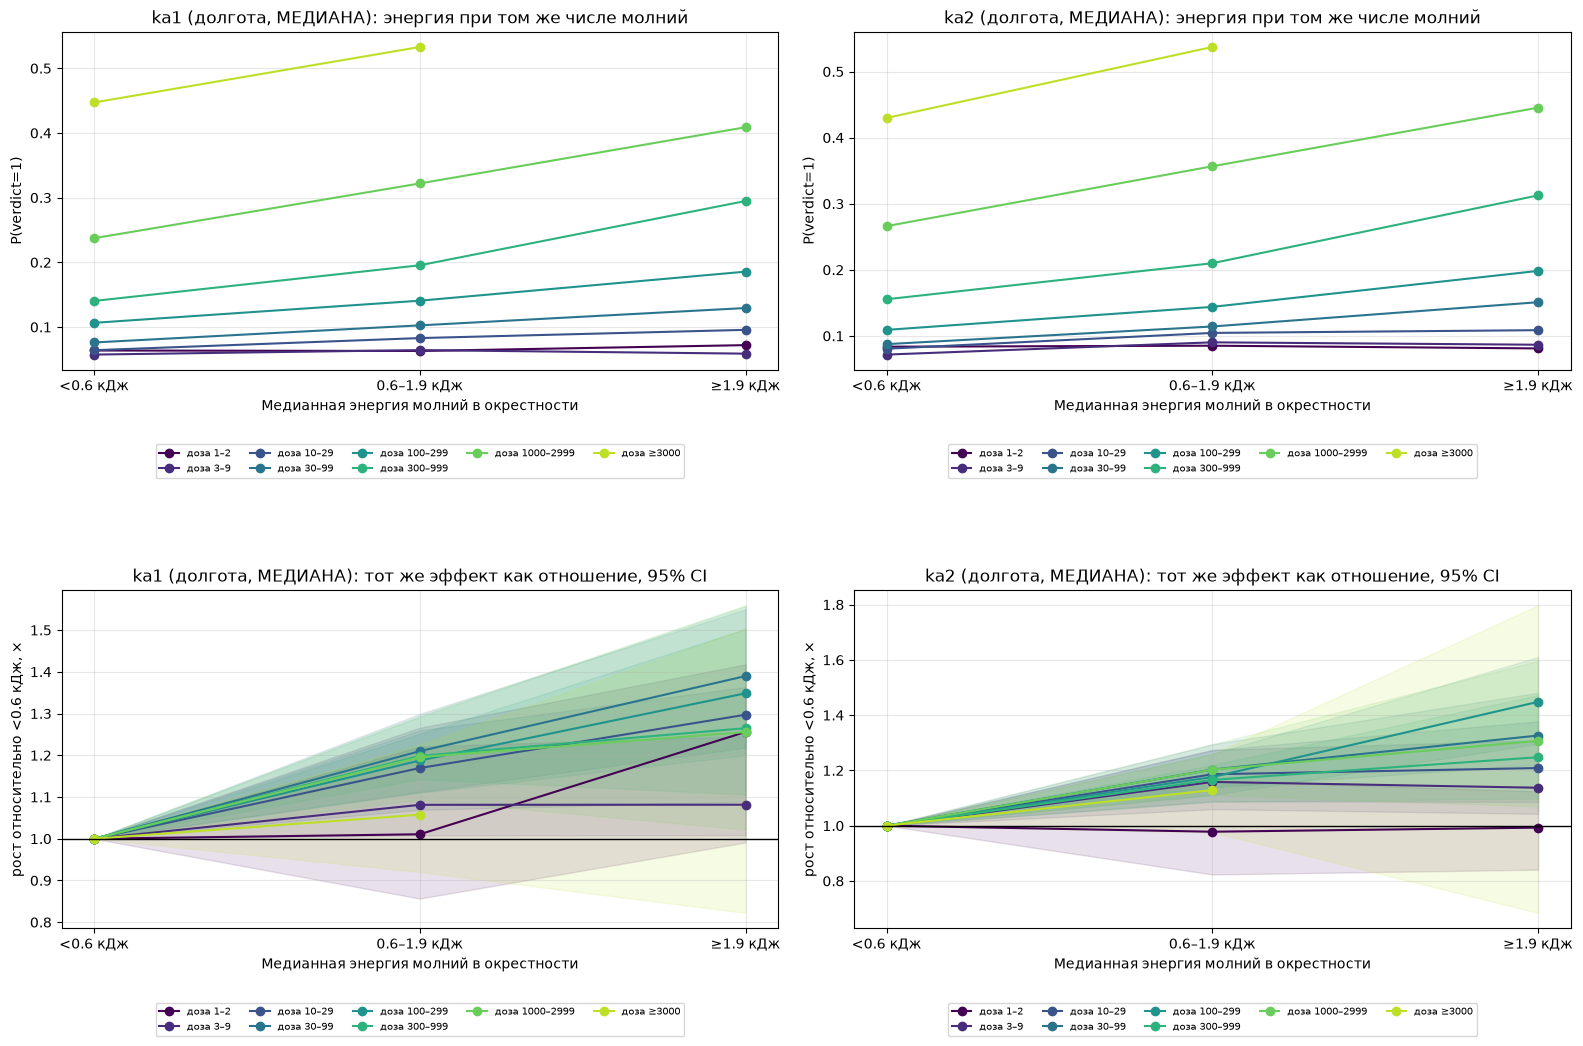

CPU times: user 12min 6s, sys: 5min 59s, total: 18min 5s
Wall time: 19min 48s


In [4]:
%%time
import importlib
import traceback

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import wwlln_common as wc
import dose_pipeline as dp
importlib.reload(dp)  # функция run_median_energy_lon только что добавлена в файл

# Терцили реального распределения энергии WWLLN (по выборке ~10.5М разрядов,
# 15 суток вразброс по году): 33-й перцентиль ~592 Дж, 66-й ~1868 Дж — округлено
# до 600/1900. Старые круглые границы 2/6 кДж были смещены далеко в верхний хвост
# (медиана ~1070 Дж < 2000!), поэтому бин "≥6кДж" почти пустой на высоких дозах
# (см. обсуждение). Терцили дают ~равный носитель в каждой из 3 групп по
# построению. e_hist_max тоже уменьшен (8000->4000, тот же n_hist_bins=16) —
# разрешение гистограммы теперь вдвое точнее именно в районе новых, более
# низких границ, без дополнительной памяти/времени.
E_EDGES_TERTILE = np.array([0.0, 600.0, 1900.0, np.inf])
E_LABELS_TERTILE = ['<0.6 кДж', '0.6–1.9 кДж', '≥1.9 кДж']

_deps = ['df', 'df_pred', 'DOSE_SC', 'acc_days', 'DOSE_R_KM', 'DOSE_DT_MIN', 'GLAT', 'GLON',
         'GDT_MIN', 'NIGHT_SZA_DEG', 'DOSE_EDGES', 'DOSE_LABELS', 'MIN_STRAT_EXP', 'N_BOOT',
         'analyze_energy_lon']
_missing = [n for n in _deps if n not in globals()]
if _missing:
    print(f'Пропущено: не определено {_missing}. Выполните ячейку «Средняя энергия при фиксированной дозе — схема «долгота»» '
          f'и загрузку перед этой.')
else:
    accum_lon_median_energy = None
    try:
        accum_lon_median_energy = dp.run_median_energy_lon(
            df, df_pred, sc_list=DOSE_SC, acc_days=acc_days,
            dose_r_km=DOSE_R_KM, dose_dt_min=DOSE_DT_MIN,
            glat=GLAT, glon=GLON, gdt_min=GDT_MIN,
            night_sza_deg=NIGHT_SZA_DEG, strata_scheme='lon', n_lonb=8,
            dose_edges=DOSE_EDGES, e_edges=E_EDGES_TERTILE,
            n_hist_bins=16, e_hist_max=4000.0,
        )
    except Exception:
        print('!!! ОШИБКА в accum_lon_median_energy — остальные ячейки ноутбука продолжат выполняться:')
        traceback.print_exc()

    if accum_lon_median_energy is not None:
        n_dose_e = accum_lon_median_energy['n_dose']
        show_bins_med = [i for i in range(1, n_dose_e)
                         if accum_lon_median_energy['exp_en_d'][..., i, :].sum() > 50 * MIN_STRAT_EXP]
        if show_bins_med:
            ncol = min(len(show_bins_med), 5)
            fig, axes = plt.subplots(2, len(DOSE_SC), figsize=(8 * len(DOSE_SC), 11.0), squeeze=False)
            for si, sc in enumerate(DOSE_SC):
                ax_a, ax_r = axes[0, si], axes[1, si]
                cmap = plt.cm.viridis(np.linspace(0, 0.9, len(show_bins_med)))
                for ci_i, db in enumerate(show_bins_med):
                    rr, ci95, p_k, nst, _ = analyze_energy_lon(accum_lon_median_energy, si, db)
                    x = np.arange(accum_lon_median_energy['n_eb'])
                    ax_a.plot(x, p_k, 'o-', color=cmap[ci_i], label=f'доза {DOSE_LABELS[db]}')
                    ax_r.plot(x, rr, 'o-', color=cmap[ci_i], label=f'доза {DOSE_LABELS[db]}')
                    ax_r.fill_between(x, ci95[0], ci95[1], color=cmap[ci_i], alpha=0.12)
                ax_r.axhline(1.0, color='k', lw=1)
                ax_a.set_ylabel('P(verdict=1)')
                ax_r.set_ylabel('рост относительно <0.6 кДж, ×')
                ax_a.set_title(f'{sc} (долгота, МЕДИАНА): энергия при том же числе молний')
                ax_r.set_title(f'{sc} (долгота, МЕДИАНА): тот же эффект как отношение, 95% CI')
                for ax in (ax_a, ax_r):
                    ax.set_xticks(np.arange(accum_lon_median_energy['n_eb']))
                    ax.set_xticklabels(E_LABELS_TERTILE)
                    ax.set_xlabel('Медианная энергия молний в окрестности')
                    ax.grid(alpha=0.3)
                    ax.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.22),
                              ncol=ncol, borderaxespad=0.)
            fig.tight_layout(rect=[0, 0.03, 1, 1])
            fig.subplots_adjust(hspace=0.65)
            plt.show()
            plt.close(fig)
        else:
            print('Нет ни одного бина дозы с достаточной экспозицией по энергии (медиана) — график не построен.')
    else:
        print('accum_lon_median_energy не посчитан — см. traceback выше, эта ячейка пропущена.')

### Интервалы для медианы энергии

Таблица роста и 95% интервала по бинам дозы и сегментам энергии для медианы. Берёт `accum_lon_median_energy`, нового прохода нет.


In [5]:
import numpy as np
import pandas as pd

_deps = ['accum_lon_median_energy', 'analyze_energy_lon', 'show_bins_med', 'DOSE_SC', 'DOSE_LABELS', 'E_LABELS_TERTILE']
_missing = [n for n in _deps if n not in globals()]
if _missing:
    print(f'Пропущено: не определено {_missing}. Выполните предыдущую ячейку (энергия, медиана, долгота) перед этой.')
elif accum_lon_median_energy is None or not show_bins_med:
    print('accum_lon_median_energy не посчитан или нет бинов с носителем — таблицу построить не из чего.')
else:
    rows = []
    for si, sc in enumerate(DOSE_SC):
        for db in show_bins_med:
            rr, ci95, p_k, nst, expo = analyze_energy_lon(accum_lon_median_energy, si, db)
            for eb in range(1, accum_lon_median_energy['n_eb']):
                if not np.isfinite(rr[eb]):
                    continue
                rows.append({
                    'КА': sc,
                    'бин дозы': DOSE_LABELS[db],
                    'энергия': f'{E_LABELS_TERTILE[eb]} vs {E_LABELS_TERTILE[0]}',
                    'рост': rr[eb],
                    'CI низ': ci95[0, eb],
                    'CI верх': ci95[1, eb],
                    'страт': int(nst[eb]),
                    'CI накрывает 1?': 'да' if ci95[0, eb] <= 1.0 <= ci95[1, eb] else 'нет',
                })
    median_energy_lon_ci_table = pd.DataFrame(rows)
    display(median_energy_lon_ci_table.round(3))
    n_total = len(median_energy_lon_ci_table)
    n_covering = (median_energy_lon_ci_table['CI накрывает 1?'] == 'да').sum()
    print(f'CI накрывает 1.0 в {n_covering} из {n_total} строк ({100*n_covering/max(n_total,1):.0f}%).')

,КА,бин дозы,энергия,рост,CI низ,CI верх,страт,CI накрывает 1?
0,ka1,1–2,0.6–1.9 кДж vs <0.6 кДж,1.011,0.857,1.266,60,да
1,ka1,1–2,≥1.9 кДж vs <0.6 кДж,1.256,0.991,1.418,66,да
2,ka1,3–9,0.6–1.9 кДж vs <0.6 кДж,1.081,1.008,1.221,108,нет
3,ka1,3–9,≥1.9 кДж vs <0.6 кДж,1.082,1.009,1.246,103,нет
4,ka1,10–29,0.6–1.9 кДж vs <0.6 кДж,1.169,1.069,1.260,119,нет
5,ka1,10–29,≥1.9 кДж vs <0.6 кДж,1.297,1.089,1.364,94,нет
6,ka1,30–99,0.6–1.9 кДж vs <0.6 кДж,1.210,1.112,1.299,148,нет
7,ka1,30–99,≥1.9 кДж vs <0.6 кДж,1.390,1.218,1.550,85,нет
8,ka1,100–299,0.6–1.9 кДж vs <0.6 кДж,1.188,1.110,1.252,136,нет
9,ka1,100–299,≥1.9 кДж vs <0.6 кДж,1.349,1.200,1.502,55,нет


CI накрывает 1.0 в 6 из 30 строк (20%).


### Сводка: где интервал медианы исключает 1

По каждому бину дозы собраны сравнения сегментов энергии с «<2 кДж» для ka1 и ka2: исключает ли 95% интервал единицу. Строится из таблицы интервалов выше.


In [6]:
import pandas as pd

_deps = ['median_energy_lon_ci_table', 'DOSE_LABELS', 'show_bins_med']
_missing = [n for n in _deps if n not in globals()]
if _missing:
    print(f'Пропущено: не определено {_missing}. Выполните предыдущую ячейку (CI таблица, медиана) перед этой.')
elif median_energy_lon_ci_table.empty:
    print('median_energy_lon_ci_table пуста — сводную таблицу построить не из чего.')
else:
    rows = []
    for db in show_bins_med:
        lab = DOSE_LABELS[db]
        sub = median_energy_lon_ci_table[median_energy_lon_ci_table['бин дозы'] == lab]
        if sub.empty:
            continue
        n_total = len(sub)
        sig = sub[sub['CI накрывает 1?'] == 'нет']
        n_sig = len(sig)
        if n_sig == 0:
            znach = 'нет, CI везде накрывает 1'
            comment = 'эффекта энергии (медиана) статистически нет'
        elif n_sig == n_total:
            znach = 'да, везде'
            growth = (sig['рост'] - 1) * 100
            comment = f'рост {growth.min():.0f}–{growth.max():.0f}%'
        else:
            znach = f'да, частично ({n_sig}/{n_total})'
            growth = (sig['рост'] - 1) * 100
            comment = f'рост {growth.min():.0f}–{growth.max():.0f}% там, где значимо'
        nst_min, nst_max = int(sub['страт'].min()), int(sub['страт'].max())
        if nst_max < 10:
            comment += f' — мало страт ({nst_min}–{nst_max}), похоже на нехватку данных'
        rows.append({
            'диапазон дозы': lab,
            'значимость (CI искл. 1)': znach,
            'коммент': comment,
            'страт (мин–макс)': f'{nst_min}–{nst_max}',
        })
    median_energy_slide_table = pd.DataFrame(rows)
    display(median_energy_slide_table)

,диапазон дозы,значимость (CI искл. 1),коммент,страт (мин–макс)
0,1–2,"нет, CI везде накрывает 1",эффекта энергии (медиана) статистически нет,60–75
1,3–9,"да, везде",рост 8–16%,103–109
2,10–29,"да, везде",рост 17–30%,94–135
3,30–99,"да, везде",рост 20–39%,85–157
4,100–299,"да, везде",рост 18–45%,55–142
5,300–999,"да, везде",рост 17–26%,29–100
6,1000–2999,"да, везде",рост 20–31%,9–48
7,≥3000,"нет, CI везде накрывает 1",эффекта энергии (медиана) статистически нет,9–11


### Какие дозы лежат внутри сегмента медианной энергии

Тот же срез, что для среднего: внутри каждого сегмента медианной энергии сумма по бинам дозы равна 100%. Источник — `accum_lon_median_energy`.


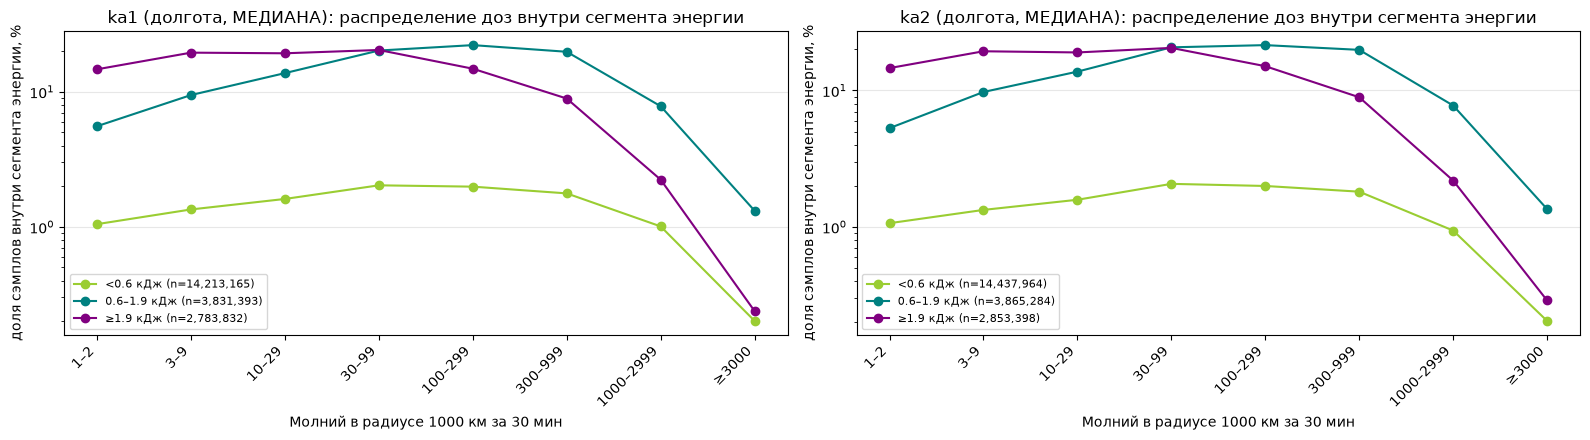

,КА,бин дозы,"<0.6 кДж, %","0.6–1.9 кДж, %","≥1.9 кДж, %"
0,ka1,0,89.01,0.00,0.00
1,ka1,1–2,1.05,5.56,14.67
2,ka1,3–9,1.34,9.45,19.48
3,ka1,10–29,1.61,13.74,19.27
4,ka1,30–99,2.03,20.19,20.39
5,ka1,100–299,1.98,22.15,14.82
6,ka1,300–999,1.77,19.77,8.91
7,ka1,1000–2999,1.01,7.82,2.23
8,ka1,≥3000,0.20,1.32,0.24
9,ka2,0,89.01,0.00,0.00


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_deps = ['accum_lon_median_energy', 'DOSE_SC', 'DOSE_LABELS', 'E_LABELS_TERTILE', 'DOSE_R_KM', 'DOSE_DT_MIN']
_missing = [n for n in _deps if n not in globals()]
if _missing:
    print(f'Пропущено: не определено {_missing}. Выполните §4.4 (энергия, медиана, долгота) перед этой.')
elif accum_lon_median_energy is None:
    print('accum_lon_median_energy не посчитан (см. traceback выше) — эта ячейка пропущена.')
else:
    n_dose_e = accum_lon_median_energy['n_dose']
    n_eb = accum_lon_median_energy['n_eb']
    dose_idx = np.arange(1, n_dose_e)  # без дозы=0 — на графике неинформативна (заглушка median_e=0)
    x = np.arange(len(dose_idx))
    LINE_COLORS = ['yellowgreen', 'teal', 'purple']

    fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(8 * len(DOSE_SC), 4.5), squeeze=False)
    dose_dist_rows = []
    for si, sc in enumerate(DOSE_SC):
        # exp_en_d: (сутки, КА, широта, долгота, сезон, ночь, доза, энергия) —
        # берём КА si, сворачиваем всё, кроме дозы и энергии
        exp_e = accum_lon_median_energy['exp_en_d'][:, si].sum(axis=(0, 1, 2, 3, 4)).astype(np.float64)
        totals = exp_e.sum(axis=0)
        pct = np.divide(exp_e, totals, out=np.zeros_like(exp_e), where=totals > 0) * 100

        ax = axes[0, si]
        for eb in range(n_eb):
            color = LINE_COLORS[eb % len(LINE_COLORS)]
            ax.plot(x, pct[dose_idx, eb], 'o-', color=color,
                   label=f'{E_LABELS_TERTILE[eb]} (n={totals[eb]:,.0f})')
        ax.set_xticks(x)
        ax.set_xticklabels([DOSE_LABELS[i] for i in dose_idx], rotation=45, ha='right')
        ax.set_ylabel('доля сэмплов внутри сегмента энергии, %')
        ax.set_xlabel(f'Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин')
        ax.set_title(f'{sc} (долгота, МЕДИАНА): распределение доз внутри сегмента энергии')
        ax.set_yscale('log')
        ax.grid(alpha=0.3, axis='y')
        ax.legend(fontsize=8)

        for db in range(n_dose_e):
            row = {'КА': sc, 'бин дозы': DOSE_LABELS[db]}
            for eb in range(n_eb):
                row[f'{E_LABELS_TERTILE[eb]}, %'] = pct[db, eb]
            dose_dist_rows.append(row)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    median_dose_energy_dist_table = pd.DataFrame(dose_dist_rows)
    display(median_dose_energy_dist_table.round(2))

### Состав энергии внутри бина дозы

На предыдущем рисунке 100% — сумма по дозам внутри фиксированной энергии. Высокий бин дозы сам по себе редкий, и столбец от этого выглядит смещённым. Здесь 100% — сумма по сегментам энергии внутри фиксированного бина дозы. Так видно, сдвинут ли состав энергии на высоких дозах. Тот же `accum_lon_median_energy`.


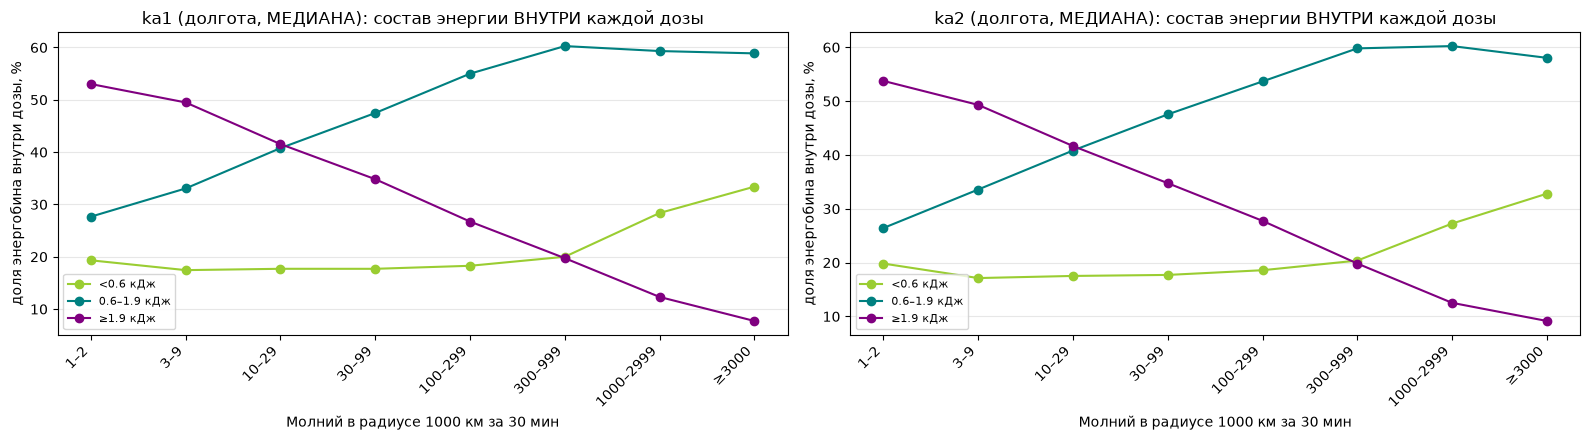

,КА,бин дозы,n (всего),"<0.6 кДж, %","0.6–1.9 кДж, %","≥1.9 кДж, %"
0,ka1,0,12651198,100.00,0.00,0.00
1,ka1,1–2,770121,19.32,27.67,53.02
2,ka1,3–9,1095635,17.45,33.06,49.49
3,ka1,10–29,1291533,17.70,40.77,41.53
4,ka1,30–99,1629591,17.70,47.47,34.83
5,ka1,100–299,1542947,18.27,54.99,26.73
6,ka1,300–999,1256994,20.00,60.27,19.73
7,ka1,1000–2999,504784,28.36,59.32,12.32
8,ka1,≥3000,85587,33.40,58.88,7.73
9,ka2,0,12851122,100.00,0.00,0.00


Если доля "≥1.9кДж" внутри дозы падает с ростом дозы — это состав, независимый от общей редкости высокой дозы (нормировка убрала этот эффект). Если держится примерно постоянной — прежний вывод про "почти нет высокой энергии на высокой дозе" был в основном артефактом нормировки по столбцу.


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_deps = ['accum_lon_median_energy', 'DOSE_SC', 'DOSE_LABELS', 'E_LABELS_TERTILE', 'DOSE_R_KM', 'DOSE_DT_MIN']
_missing = [n for n in _deps if n not in globals()]
if _missing:
    print(f'Пропущено: не определено {_missing}. Выполните §4.4 (энергия, медиана, долгота) перед этой.')
elif accum_lon_median_energy is None:
    print('accum_lon_median_energy не посчитан — эта ячейка пропущена.')
else:
    n_dose_e = accum_lon_median_energy['n_dose']
    n_eb = accum_lon_median_energy['n_eb']
    dose_idx = np.arange(1, n_dose_e)  # без дозы=0 — там 100% приходится на заглушку median_e=0
    x = np.arange(len(dose_idx))
    LINE_COLORS = ['yellowgreen', 'teal', 'purple']

    fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(8 * len(DOSE_SC), 4.5), squeeze=False)
    row_norm_rows = []
    for si, sc in enumerate(DOSE_SC):
        exp_e = accum_lon_median_energy['exp_en_d'][:, si].sum(axis=(0, 1, 2, 3, 4)).astype(np.float64)
        # нормировка по СТРОКЕ (сумма по энергии для каждой дозы = 100%) — убирает
        # эффект "высокая доза сама по себе редкая", показывает состав ВНУТРИ дозы
        row_totals = exp_e.sum(axis=1, keepdims=True)
        pct_row = np.divide(exp_e, row_totals, out=np.zeros_like(exp_e), where=row_totals > 0) * 100

        ax = axes[0, si]
        for eb in range(n_eb):
            color = LINE_COLORS[eb % len(LINE_COLORS)]
            ax.plot(x, pct_row[dose_idx, eb], 'o-', color=color, label=E_LABELS_TERTILE[eb])
        ax.set_xticks(x)
        ax.set_xticklabels([DOSE_LABELS[i] for i in dose_idx], rotation=45, ha='right')
        ax.set_ylabel('доля энергобина внутри дозы, %')
        ax.set_xlabel(f'Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин')
        ax.set_title(f'{sc} (долгота, МЕДИАНА): состав энергии ВНУТРИ каждой дозы')
        ax.grid(alpha=0.3, axis='y')
        ax.legend(fontsize=8)

        for db in range(n_dose_e):
            row = {'КА': sc, 'бин дозы': DOSE_LABELS[db], 'n (всего)': int(row_totals[db, 0])}
            for eb in range(n_eb):
                row[f'{E_LABELS_TERTILE[eb]}, %'] = pct_row[db, eb]
            row_norm_rows.append(row)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    median_energy_row_norm_table = pd.DataFrame(row_norm_rows)
    display(median_energy_row_norm_table.round(2))
    print('Если доля "≥1.9кДж" внутри дозы падает с ростом дозы — это состав, независимый '
          'от общей редкости высокой дозы (нормировка убрала этот эффект). Если держится '
          'примерно постоянной — прежний вывод про "почти нет высокой энергии на высокой '
          'дозе" был в основном артефактом нормировки по столбцу.')


### Концентрация вклада по осям — схема «долгота»

Полная страта — комбинация широты, долготы, сезона и ночи. Здесь для каждой оси остальные три свёрнуты. Таблица показывает, какая доля веса сравнения MH сидит в одном и в двух самых тяжёлых значениях оси, и в каком диапазоне лежит рост по значениям, где носитель есть. Накопитель — `accum_lon`. Отчётный бин на сохранённом прогоне — «≥3000».


In [8]:
import numpy as np
import pandas as pd
import wwlln_common as wc
import dose_pipeline as dp

_ac_deps = ['accum_lon', 'RES_LON', 'DOSE_SC', 'DOSE_LABELS', 'REF_BIN', 'MIN_STRAT_EXP', 'MIN_REPORT_EXP']
_missing = [n for n in _ac_deps if n not in globals()]
if _missing:
    print(f'Пропущено: не определено {_missing}. Выполните расчёт §4.4 «Долгота вместо местного времени» перед этой.')
elif accum_lon is None:
    print('accum_lon не посчитан (см. traceback в §4.4) — эта ячейка пропущена.')
else:
    def axis_concentration(accum, sc_i, k, ref, min_exp):
        """Вклад в MH-сравнение (бин k vs ref), разложенный по каждой оси страты
        отдельно (остальные оси свёрнуты). Показывает: 1) не сидит ли почти весь
        вес MH в 1-2 значениях какой-то оси; 2) растёт ли P(verdict) почти во
        всех значениях оси, а не только в топовых по весу."""
        n_latb, n_lonb = accum['n_latb'], accum['n_axis4']
        w_lat, w_lon = 180.0 / n_latb, 360.0 / n_lonb
        axis_defs = [
            ('широта', [f'{-90 + w_lat * i:.0f}\u2026{-90 + w_lat * (i + 1):.0f}' for i in range(n_latb)]),
            ('долгота', [f'{-180 + w_lon * i:.0f}\u2026{-180 + w_lon * (i + 1):.0f}' for i in range(n_lonb)]),
            ('сезон', list(wc.SEASON_ORDER)),
            ('ночь/день', ['день', 'ночь']),
        ]
        Et_full = accum['exp_true_d'][:, sc_i].sum(axis=0)   # (широта, долгота, сезон, ночь, доза)
        Pt_full = accum['pos_true_d'][:, sc_i].sum(axis=0)
        e0, e1 = Et_full[..., ref].astype(np.float64), Et_full[..., k].astype(np.float64)
        p0, p1 = Pt_full[..., ref].astype(np.float64), Pt_full[..., k].astype(np.float64)
        ok = (e0 >= min_exp) & (e1 >= min_exp)
        tot = np.where(e0 + e1 > 0, e0 + e1, 1.0)
        w = np.where(ok, e0 * e1 / tot, 0.0)
        num = np.where(ok, p1 * e0 / tot, 0.0)
        den = np.where(ok, p0 * e1 / tot, 0.0)
        total_w = w.sum()

        rows = []
        for axis_i, (axis_name, labels) in enumerate(axis_defs):
            other = tuple(a for a in range(4) if a != axis_i)
            w_v = w.sum(axis=other)
            num_v = num.sum(axis=other)
            den_v = den.sum(axis=other)
            share = 100 * w_v / total_w if total_w > 0 else np.full_like(w_v, np.nan)
            order = np.argsort(-share)
            valid = den_v > 0
            rr_v = np.divide(num_v, den_v, out=np.full_like(num_v, np.nan), where=valid)
            top2 = share[order[:2]].sum()
            rows.append({
                'ось': axis_name,
                'знач. с макс. вкладом': labels[order[0]],
                'доля макс, %': share[order[0]],
                'доля топ-2, %': top2,
                'значений с носителем': f'{int(valid.sum())}/{len(labels)}',
                'RR мин/медиана/макс': (f'{np.nanmin(rr_v[valid]):.2f}/'
                                        f'{np.nanmedian(rr_v[valid]):.2f}/'
                                        f'{np.nanmax(rr_v[valid]):.2f}') if valid.any() else '\u2014',
                'подозрительно?': ('да, >50%' if top2 > 50 else '') if len(labels) > 2 else '(бинарная ось)',
            })
        return pd.DataFrame(rows)

    all_rows = []
    for si, sc in enumerate(DOSE_SC):
        r = RES_LON.get(sc)
        if r is None:
            continue
        k = dp.report_bin(r, min_exp=MIN_REPORT_EXP, min_strata=5, ref_bin=REF_BIN)
        if k is None:
            continue
        t = axis_concentration(accum_lon, si, k, REF_BIN, MIN_STRAT_EXP)
        t.insert(0, 'КА', sc)
        t.insert(1, 'бин', DOSE_LABELS[k])
        all_rows.append(t)

    if all_rows:
        axis_conc_lon = pd.concat(all_rows, ignore_index=True)
        display(axis_conc_lon.round(2))
        print('Если "доля топ-2" по всем осям заметно меньше 100% и RR-мин остаётся выше 1 \u2014 '
              'рост не сидит в 1-2 значениях одной оси (широты/долготы/сезона/дня-ночи), '
              'а размазан по большинству значений с носителем.')
    else:
        print('Нет ни одного КА с отчётным бином в RES_LON \u2014 таблицу построить не из чего.')


,КА,бин,ось,знач. с макс. вкладом,"доля макс, %","доля топ-2, %",значений с носителем,RR мин/медиана/макс,подозрительно?
0,ka1,≥3000,широта,15…30,49.05,80.00,5/12,1.34/2.72/4.06,"да, >50%"
1,ka1,≥3000,долгота,-135…-90,66.39,97.83,3/8,2.06/2.68/3.30,"да, >50%"
2,ka1,≥3000,сезон,весна,48.18,90.67,4/4,2.80/3.09/14.60,"да, >50%"
3,ka1,≥3000,ночь/день,ночь,59.43,100.00,2/2,2.15/5.23/8.31,(бинарная ось)
4,ka2,≥3000,широта,15…30,50.11,78.36,6/12,1.77/2.28/3.95,"да, >50%"
5,ka2,≥3000,долгота,-135…-90,64.90,97.09,3/8,1.77/2.35/2.59,"да, >50%"
6,ka2,≥3000,сезон,лето,47.33,93.79,3/4,2.22/2.57/4.30,"да, >50%"
7,ka2,≥3000,ночь/день,ночь,62.35,100.00,2/2,1.83/3.91/5.99,(бинарная ось)


Если "доля топ-2" по всем осям заметно меньше 100% и RR-мин остаётся выше 1 — рост не сидит в 1-2 значениях одной оси (широты/долготы/сезона/дня-ночи), а размазан по большинству значений с носителем.


### День и ночь — схема «долгота»

Те же накопители `accum_lon`, два вызова анализа: день и ночь отдельно. Нового прохода по 255 суткам нет. Ночь — зенитный угол Солнца больше 98° на поверхности.


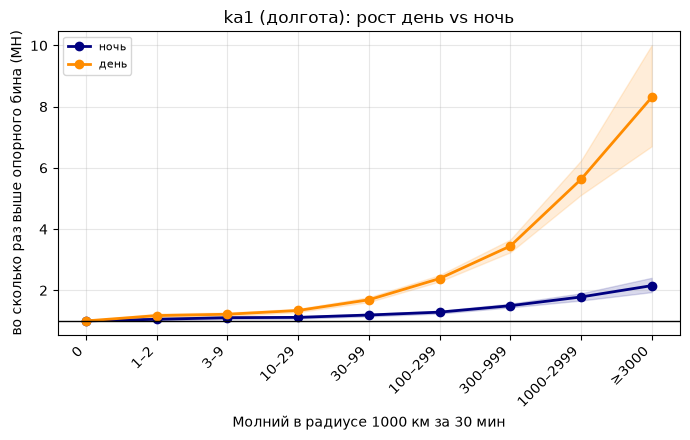

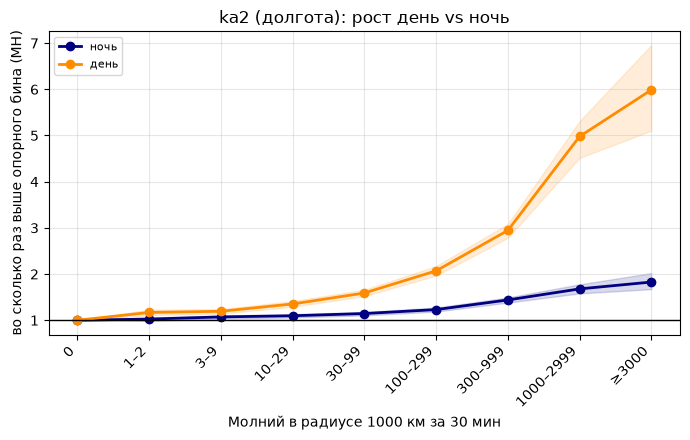

,КА,условия,бин,рост MH,CI,рост null,сверх null,CI сверх null
0,ka1,ночь,≥3000,2.153,1.94–2.41,1.751,1.230,1.14–1.34
1,ka1,день,≥3000,8.306,6.71–10.01,3.346,2.483,1.95–2.99
2,ka2,ночь,≥3000,1.827,1.67–2.02,1.656,1.103,1.04–1.18
3,ka2,день,≥3000,5.987,5.10–6.96,2.579,2.321,1.87–2.79


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_deps = ['accum_lon', 'DOSE_SC', 'DOSE_LABELS', 'REF_BIN', 'MIN_STRAT_EXP', 'MIN_REPORT_EXP', 'N_BOOT',
         'DOSE_R_KM', 'DOSE_DT_MIN']
_missing = [n for n in _deps if n not in globals()]
if _missing:
    print(f'Пропущено: не определено {_missing}. Выполните расчёт §4.4 «Долгота вместо местного времени» перед этой.')
elif accum_lon is None:
    print('accum_lon не посчитан (см. traceback в §4.4) \u2014 эта ячейка пропущена.')
else:
    x_lon = np.arange(accum_lon['n_dose'])
    colors = {1: 'navy', 0: 'darkorange'}
    labels = {1: 'ночь', 0: 'день'}
    RES_LON_NIGHT = {}
    for si, sc in enumerate(DOSE_SC):
        fig, ax = plt.subplots(figsize=(7, 4.5))
        for night in (1, 0):
            r = dp.analyze(accum_lon, sc=si, night=night, n_boot=N_BOOT, ref_bin=REF_BIN,
                           min_strat_exp=MIN_STRAT_EXP)
            RES_LON_NIGHT[(sc, night)] = r
            ax.plot(x_lon, r['rr_t'], 'o-', color=colors[night], lw=2, label=labels[night])
            ax.fill_between(x_lon, r['ci_t'][0], r['ci_t'][1], color=colors[night], alpha=0.15)
        ax.axhline(1.0, color='k', lw=1)
        ax.set_xticks(x_lon)
        ax.set_xticklabels(DOSE_LABELS, rotation=45, ha='right')
        ax.set_xlabel(f'Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин')
        ax.set_ylabel('во сколько раз выше опорного бина (MH)')
        ax.set_title(f'{sc} (долгота): рост день vs ночь')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
        fig.tight_layout()
        plt.show()
        plt.close(fig)

    rows = []
    for si, sc in enumerate(DOSE_SC):
        for night, lab in [(1, 'ночь'), (0, 'день')]:
            r = RES_LON_NIGHT[(sc, night)]
            k = dp.report_bin(r, min_exp=MIN_REPORT_EXP, min_strata=5, ref_bin=REF_BIN)
            if k is None:
                rows.append({'КА': sc, 'условия': lab, 'бин': 'нет носителя'})
                continue
            rows.append({
                'КА': sc, 'условия': lab, 'бин': DOSE_LABELS[k],
                'рост MH': r['rr_t'][k], 'CI': f"{r['ci_t'][0, k]:.2f}\u2013{r['ci_t'][1, k]:.2f}",
                'рост null': r['rr_n'][k], 'сверх null': r['rrr'][k],
                'CI сверх null': f"{r['ci_rrr'][0, k]:.2f}\u2013{r['ci_rrr'][1, k]:.2f}",
            })
    day_night_lon_summary = pd.DataFrame(rows)
    display(day_night_lon_summary.round(3))


## 4.5. Footprint и магнитно-сопряжённая точка, схема LST

Доза в блоках выше искалась вокруг точки под спутником. Источник свиста на коротком скачке ближе к следу силовой линии в ионосфере (footprint), на распространении вдоль силовой линии — к магнитно-сопряжённой точке в другом полушарии.

Координаты считает AACGM-v2 (`aacgmv2`): точка спутника на высоте 827 км переводится на высоту 100 км (footprint) или туда же с обратным знаком широты (сопряжённая точка). Доза ищется вокруг этой точки. Страты — широта, местное время, сезон, ночь — и экспозиция остаются у подспутниковой точки: от неё зависит, прозрачна ли ионосфера на приёмнике. Лаги null только назад, как в первом расчёте.

На 8 сутках перед полным прогоном экспозиция и число `verdict=1` у трёх геометрий совпали, а отношение к опорному бину разошлось: под спутником 2.28, footprint 2.59, сопряжённая точка 1.57.


Накопители: 81 МБ; сетки строим для 300 дней (схема страт='lst', лаги=(3, 7, 14) назад, сезонный фильтр=вкл)
  ... 20/300 дней
  ... 40/300 дней
  ... 60/300 дней
  ... 80/300 дней
  ... 100/300 дней
  ... 120/300 дней
  ... 140/300 дней
  ... 160/300 дней
  ... 180/300 дней
  ... 200/300 дней
  ... 220/300 дней
  ... 240/300 дней
  ... 260/300 дней
  ... 280/300 дней
  ... 300/300 дней
Готово. Экспозиция: 41,985,036 сэмплов, verdict=1: 3,816,529 (9.09%); экспозиция null: 118,012,442 (в среднем 2.81 лага/сутки использовано из 3 возможных)
Накопители: 81 МБ; сетки строим для 300 дней (схема страт='lst', лаги=(3, 7, 14) назад, сезонный фильтр=вкл)
  ... 20/300 дней
  ... 40/300 дней
  ... 60/300 дней
  ... 80/300 дней
  ... 100/300 дней
  ... 120/300 дней
  ... 140/300 дней
  ... 160/300 дней
  ... 180/300 дней
  ... 200/300 дней
  ... 220/300 дней
  ... 240/300 дней
  ... 260/300 дней
  ... 280/300 дней
  ... 300/300 дней
Готово. Экспозиция: 41,985,036 сэмплов, verdict=1: 3,816,529 (9.0

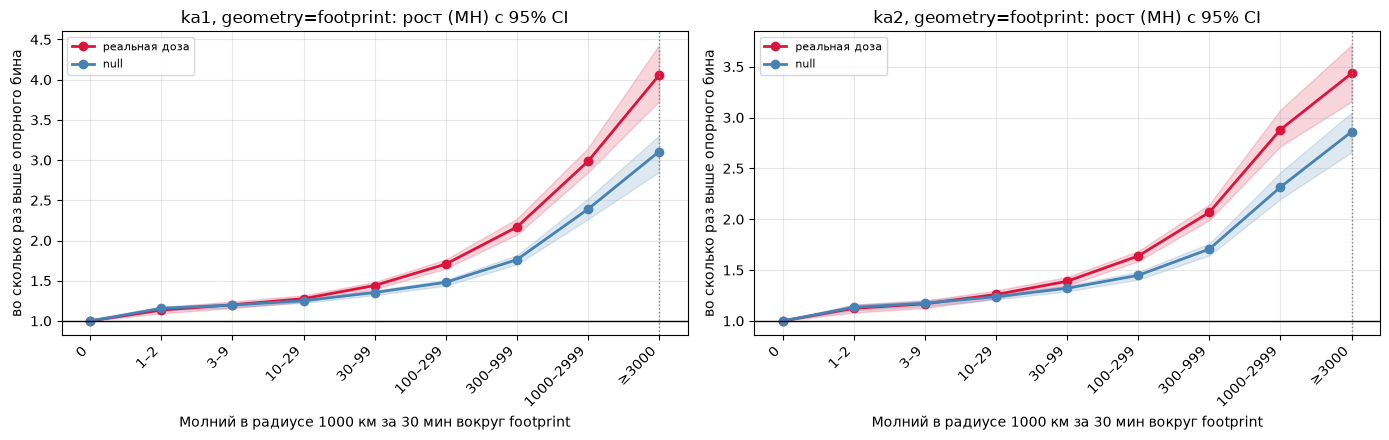

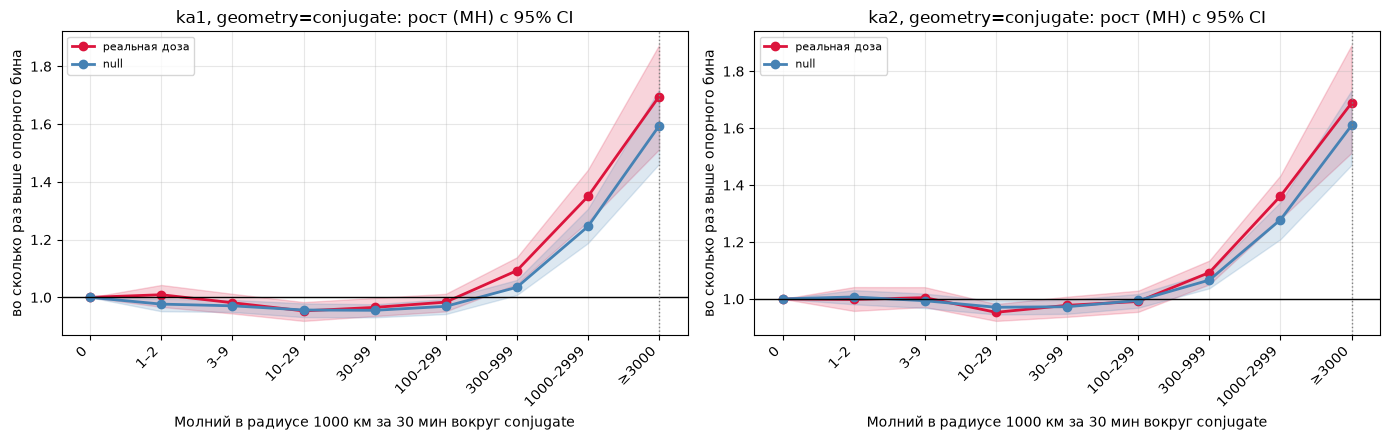

,КА,geometry,бин дозы,рост MH,рост null,сверх null,CI сверх null
0,ka1,satellite (основной блок),≥3000,4.192,3.271,1.282,1.20–1.36
1,ka1,footprint,≥3000,4.055,3.106,1.306,1.23–1.39
2,ka1,conjugate,≥3000,1.695,1.594,1.064,0.98–1.15
3,ka2,satellite (основной блок),≥3000,3.651,2.968,1.230,1.16–1.31
4,ka2,footprint,≥3000,3.433,2.860,1.201,1.13–1.26
5,ka2,conjugate,≥3000,1.688,1.610,1.049,0.97–1.13


Если footprint/conjugate дают заметно более сильный и/или более узкий по CI эффект, чем satellite — подспутниковая точка была занижающим приближением, и физически осмысленная геометрия (footprint для fractional-hop, conjugate для ducted) ловит источник точнее. Если хуже/такой же — на этих спутниках/высоте либо fractional-hop уже был близко к подспутниковой точке, либо разрешение сетки (2°) смазывает разницу.
CPU times: user 8min 33s, sys: 3min 24s, total: 11min 58s
Wall time: 12min 32s


In [11]:
%%time
import traceback

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import wwlln_common as wc
import dose_pipeline as dp

accum_geo = {}
try:
    wc.require_globals(globals(), ['df', 'df_pred', 'DOSE_SC', 'acc_days', 'DOSE_R_KM', 'DOSE_DT_MIN', 'GLAT', 'GLON', 'GDT_MIN', 'NULL_LAGS', 'NULL_SYMMETRIC', 'NULL_SEASON_SAFE', 'NIGHT_SZA_DEG', 'STRATA_SCHEME', 'DOSE_EDGES', 'DOSE_LABELS', 'MIN_STRAT_EXP', 'MIN_REPORT_EXP', 'N_BOOT', 'REF_BIN'], hint='выполните ячейку 94583c9b (основной блок, загрузка) перед этой')
    for geom in ['footprint', 'conjugate']:
        accum_geo[geom] = dp.run_accumulation(
            df, df_pred, sc_list=DOSE_SC, acc_days=acc_days,
            dose_r_km=DOSE_R_KM, dose_dt_min=DOSE_DT_MIN,
            glat=GLAT, glon=GLON, gdt_min=GDT_MIN,
            null_lags=NULL_LAGS, null_symmetric=NULL_SYMMETRIC, null_season_safe=NULL_SEASON_SAFE,
            do_energy=False, night_sza_deg=NIGHT_SZA_DEG, strata_scheme=STRATA_SCHEME,
            geometry=geom, dose_edges=DOSE_EDGES,
        )
except Exception:
    print('!!! ОШИБКА в accum_geo — остальные ячейки ноутбука продолжат выполняться:')
    traceback.print_exc()
    accum_geo = {}

RES_GEO = {}
if accum_geo:
    x_geo = np.arange(N_DOSE)
    for geom in ['footprint', 'conjugate']:
        fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5), squeeze=False)
        for si, sc in enumerate(DOSE_SC):
            r = dp.analyze(accum_geo[geom], sc=si, n_boot=N_BOOT, ref_bin=REF_BIN,
                           min_strat_exp=MIN_STRAT_EXP)
            RES_GEO[(geom, sc)] = r
            rb = dp.report_bin(r, min_exp=MIN_REPORT_EXP, min_strata=5, ref_bin=REF_BIN)

            ax = axes[0, si]
            ax.plot(x_geo, r['rr_t'], 'o-', color='crimson', lw=2, label='реальная доза')
            ax.fill_between(x_geo, r['ci_t'][0], r['ci_t'][1], color='crimson', alpha=0.18)
            ax.plot(x_geo, r['rr_n'], 'o-', color='steelblue', lw=2, label='null')
            ax.fill_between(x_geo, r['ci_n'][0], r['ci_n'][1], color='steelblue', alpha=0.18)
            ax.axhline(1.0, color='k', lw=1)
            if rb is not None:
                ax.axvline(rb, color='gray', ls=':', lw=1)
            ax.set_xticks(x_geo)
            ax.set_xticklabels(DOSE_LABELS, rotation=45, ha='right')
            ax.set_xlabel(f'Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин вокруг {geom}')
            ax.set_ylabel('во сколько раз выше опорного бина')
            ax.set_title(f'{sc}, geometry={geom}: рост (MH) с 95% CI')
            ax.grid(alpha=0.3)
            ax.legend(fontsize=8)
        fig.tight_layout()
        plt.show()
        plt.close(fig)

    # --- сводка: satellite vs footprint vs conjugate ---
    rows = []
    for si, sc in enumerate(DOSE_SC):
        for label, res_dict, key in [('satellite (основной блок)', RES if 'RES' in globals() else {}, sc),
                                     ('footprint', RES_GEO, ('footprint', sc)),
                                     ('conjugate', RES_GEO, ('conjugate', sc))]:
            r = res_dict.get(key)
            if r is None:
                rows.append({'КА': sc, 'geometry': label, 'бин дозы': 'нет данных'})
                continue
            b = dp.report_bin(r, min_exp=MIN_REPORT_EXP, min_strata=5, ref_bin=REF_BIN)
            if b is None:
                rows.append({'КА': sc, 'geometry': label, 'бин дозы': 'нет носителя'})
                continue
            rows.append({
                'КА': sc, 'geometry': label, 'бин дозы': DOSE_LABELS[b],
                'рост MH': r['rr_t'][b], 'рост null': r['rr_n'][b], 'сверх null': r['rrr'][b],
                'CI сверх null': f"{r['ci_rrr'][0,b]:.2f}–{r['ci_rrr'][1,b]:.2f}",
            })
    geometry_summary = pd.DataFrame(rows)
    display(geometry_summary.round(3))
    print('Если footprint/conjugate дают заметно более сильный и/или более узкий по CI эффект, '
          'чем satellite — подспутниковая точка была занижающим приближением, и физически '
          'осмысленная геометрия (footprint для fractional-hop, conjugate для ducted) ловит '
          'источник точнее. Если хуже/такой же — на этих спутниках/высоте либо fractional-hop '
          'уже был близко к подспутниковой точке, либо разрешение сетки (2°) смазывает разницу.')
else:
    print('accum_geo не посчитан — см. traceback выше, эта ячейка пропущена.')


## 4.6. ka4, схема «долгота»

Тот же отдельный прогон ka4, что в §4.1, со стратами широта × долгота × сезон × ночь. Окно те же 10 суток, интервал бутстрапа такой же грубый. Если загрузка ka4 из §4.1 уже есть в памяти, ячейка её берёт.


Накопители: 0 МБ; сетки строим для 26 дней (схема страт='lon', лаги=(3, 7, 14) назад, сезонный фильтр=вкл)
  ... 20/26 дней
Готово. Экспозиция: 693,512 сэмплов, verdict=1: 160,755 (23.18%); экспозиция null: 2,080,536 (в среднем 3.00 лага/сутки использовано из 3 возможных)


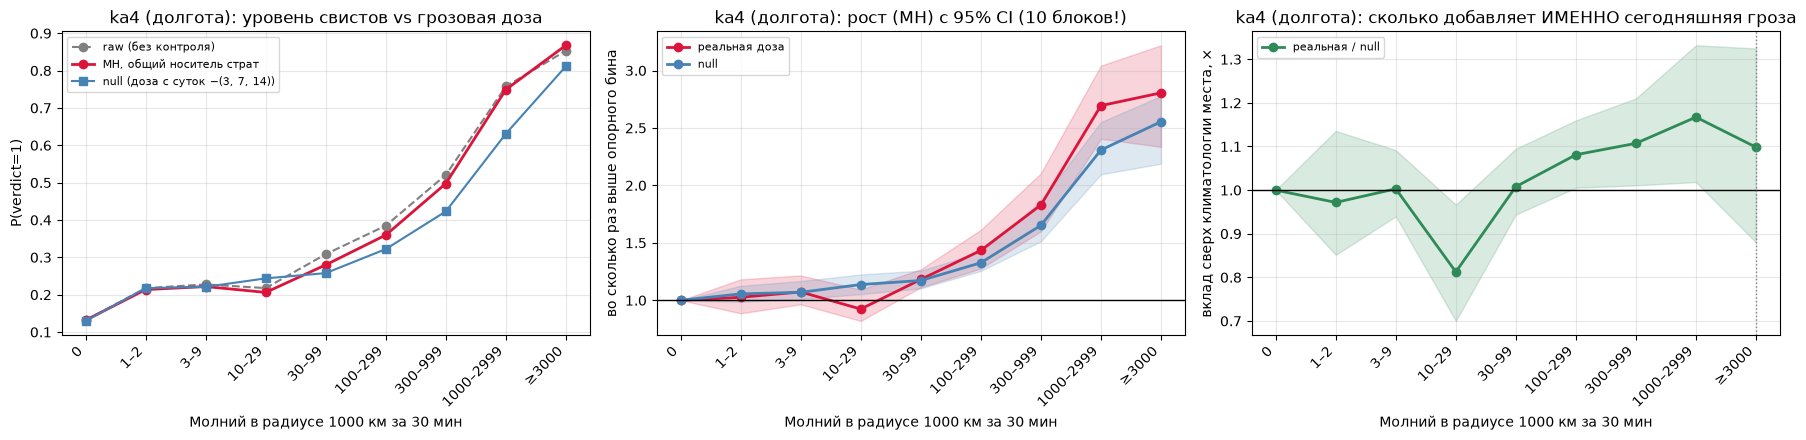

ka4 (долгота): бин=≥3000, сверх null=1.10 CI=[0.88,1.32] — разведочный сигнал, сравнивайте направление, не точное число, с §4.1 (ka4/LST).
CPU times: user 7.52 s, sys: 2.15 s, total: 9.68 s
Wall time: 10.5 s


In [12]:
%%time
import traceback

import numpy as np
import matplotlib.pyplot as plt

import wwlln_common as wc
import dose_pipeline as dp

if 'df_ka4' not in globals():
    KA4_SC = ('ka4',)
    KA4_DAYS = wc.analysis_days(_paths_d['pred'], _paths_d['ae'], KA4_SC)
    KA4_MAX_LAG = max(NULL_LAGS)
    _ka4_dc = wc.day_codes(KA4_DAYS)
    KA4_AE_DAYS = [str(np.datetime64(int(c), 'D')).replace('-', '')
                  for c in range(int(_ka4_dc.min()) - KA4_MAX_LAG - 1, int(_ka4_dc.max()) + 1)]
    _cache = _paths_d['cache'] / 'AE_20250101_20251231.parquet'
    df_ka4 = wc.load_ae(ae_dir=_paths_d['ae'], cache_path=_cache, days=KA4_AE_DAYS, verbose=True)
    df_pred_ka4 = wc.load_predictions(_paths_d['pred'], sc_list=KA4_SC, days=KA4_DAYS, verbose=True)
    ka4_acc_days = sorted(int(d) for d in _ka4_dc)

KA4_LON_N_LATB, KA4_LON_N_LONB = 6, 4
KA4_MIN_STRAT_EXP, KA4_MIN_REPORT_EXP = 150, 1500

accum_ka4_lon = None
try:
    wc.require_globals(globals(), ['_paths_d', 'NULL_LAGS', 'DOSE_R_KM', 'DOSE_DT_MIN', 'GLAT', 'GLON', 'GDT_MIN', 'NIGHT_SZA_DEG', 'DOSE_LABELS'], hint='выполните ячейку 94583c9b (основной блок, загрузка) перед этой')
    accum_ka4_lon = dp.run_accumulation(
        df_ka4, df_pred_ka4, sc_list=('ka4',), acc_days=ka4_acc_days,
        dose_r_km=DOSE_R_KM, dose_dt_min=DOSE_DT_MIN, glat=GLAT, glon=GLON, gdt_min=GDT_MIN,
        null_lags=NULL_LAGS, null_symmetric=False, null_season_safe=True,
        do_energy=False, night_sza_deg=NIGHT_SZA_DEG, strata_scheme='lon',
        n_latb=KA4_LON_N_LATB, n_lonb=KA4_LON_N_LONB,
    )
except Exception:
    print('!!! ОШИБКА в accum_ka4_lon — остальные ячейки ноутбука продолжат выполняться:')
    traceback.print_exc()

if accum_ka4_lon is not None:
    x_ka4_lon = np.arange(accum_ka4_lon['n_dose'])
    RES_KA4_LON = {}
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    r = dp.analyze(accum_ka4_lon, sc=0, n_boot=200, ref_bin=0, min_strat_exp=KA4_MIN_STRAT_EXP)
    RES_KA4_LON['все'] = r
    rb = dp.report_bin(r, min_exp=KA4_MIN_REPORT_EXP, min_strata=3, ref_bin=0)

    axes[0].plot(x_ka4_lon, r['raw'], 'o--', color='gray', lw=1.5, label='raw (без контроля)')
    axes[0].plot(x_ka4_lon, r['pk_t'], 'o-', color='crimson', lw=2, label='MH, общий носитель страт')
    axes[0].plot(x_ka4_lon, r['pk_n'], 's-', color='steelblue', label=f'null (доза с суток −{NULL_LAGS})')
    axes[0].plot(x_ka4_lon, r['p0_t'], '.:', color='crimson', alpha=0.5, lw=1,
                label='уровень опорного бина на тех же стратах')
    axes[0].set_ylabel('P(verdict=1)')
    axes[0].set_title('ka4 (долгота): уровень свистов vs грозовая доза')

    axes[1].plot(x_ka4_lon, r['rr_t'], 'o-', color='crimson', lw=2, label='реальная доза')
    axes[1].fill_between(x_ka4_lon, r['ci_t'][0], r['ci_t'][1], color='crimson', alpha=0.18)
    axes[1].plot(x_ka4_lon, r['rr_n'], 'o-', color='steelblue', lw=2, label='null')
    axes[1].fill_between(x_ka4_lon, r['ci_n'][0], r['ci_n'][1], color='steelblue', alpha=0.18)
    axes[1].axhline(1.0, color='k', lw=1)
    axes[1].set_ylabel('во сколько раз выше опорного бина')
    axes[1].set_title('ka4 (долгота): рост (MH) с 95% CI (10 блоков!)')

    axes[2].plot(x_ka4_lon, r['rrr'], 'o-', color='seagreen', lw=2, label='реальная / null')
    axes[2].fill_between(x_ka4_lon, r['ci_rrr'][0], r['ci_rrr'][1], color='seagreen', alpha=0.18)
    axes[2].axhline(1.0, color='k', lw=1)
    if rb is not None:
        axes[2].axvline(rb, color='gray', ls=':', lw=1)
    axes[2].set_ylabel('вклад сверх климатологии места, ×')
    axes[2].set_title('ka4 (долгота): сколько добавляет ИМЕННО сегодняшняя гроза')

    for ax in axes:
        ax.set_xticks(x_ka4_lon)
        ax.set_xticklabels(DOSE_LABELS, rotation=45, ha='right')
        ax.set_xlabel(f'Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    if rb is not None:
        print(f'ka4 (долгота): бин={DOSE_LABELS[rb]}, сверх null={r["rrr"][rb]:.2f} '
              f'CI=[{r["ci_rrr"][0,rb]:.2f},{r["ci_rrr"][1,rb]:.2f}] — '
              f'разведочный сигнал, сравнивайте направление, не точное число, с §4.1 (ka4/LST).')
    else:
        print('ka4 (долгота): нет бина с достаточным носителем.')
else:
    print('accum_ka4_lon не посчитан — см. traceback выше, эта ячейка пропущена.')


## 4.7. Радиус, окно и порог ночи — схема «долгота»

Проверка, держится ли вывод при другом размере окрестности и другом пороге ночи. Радиусы 500, 1000 и 2000 км, окна 15, 30 и 60 мин — все девять пар. Порог ночи — зенитный угол 90°, 94°, 98°, 102° и 108°. В остальных блоках порог 98°. Схема страт «долгота». Сетки молний и спутника строятся один раз на весь набор.


Sweep R/Δt: 9 пар, накопители ~726 МБ суммарно; сетки молний/спутника — общие, строятся один раз
  ... 40/300 дней
  ... 80/300 дней
  ... 120/300 дней
  ... 160/300 дней
  ... 200/300 дней
  ... 240/300 дней
  ... 280/300 дней
  R=500км Δt=15мин: экспозиция=41,985,036, verdict=1=3,816,529 (9.09%)
  R=500км Δt=30мин: экспозиция=41,985,036, verdict=1=3,816,529 (9.09%)
  R=500км Δt=60мин: экспозиция=41,985,036, verdict=1=3,816,529 (9.09%)
  R=1000км Δt=15мин: экспозиция=41,985,036, verdict=1=3,816,529 (9.09%)
  R=1000км Δt=30мин: экспозиция=41,985,036, verdict=1=3,816,529 (9.09%)
  R=1000км Δt=60мин: экспозиция=41,985,036, verdict=1=3,816,529 (9.09%)
  R=2000км Δt=15мин: экспозиция=41,985,036, verdict=1=3,816,529 (9.09%)
  R=2000км Δt=30мин: экспозиция=41,985,036, verdict=1=3,816,529 (9.09%)
  R=2000км Δt=60мин: экспозиция=41,985,036, verdict=1=3,816,529 (9.09%)


,"R, км","Δt, мин",КА,бин,сверх null,CI
0,500.0,15,ka1,1000–2999,1.383,1.29–1.51
1,500.0,15,ka2,1000–2999,1.400,1.25–1.50
2,500.0,30,ka1,1000–2999,1.325,1.28–1.39
3,500.0,30,ka2,1000–2999,1.283,1.23–1.37
4,500.0,60,ka1,≥3000,1.294,1.23–1.39
5,500.0,60,ka2,≥3000,1.342,1.24–1.43
6,1000.0,15,ka1,1000–2999,1.331,1.24–1.41
7,1000.0,15,ka2,1000–2999,1.342,1.23–1.43
8,1000.0,30,ka1,≥3000,1.329,1.19–1.46
9,1000.0,30,ka2,≥3000,1.228,1.11–1.34


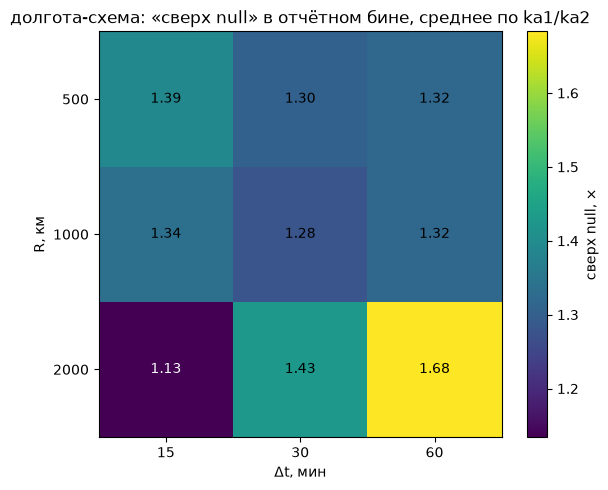

Sweep NIGHT_SZA_DEG: 5 порогов [90.0, 94.0, 98.0, 102.0, 108.0], накопители ~403 МБ суммарно; доза общая, считается один раз
  ... 40/300 дней
  ... 80/300 дней
  ... 120/300 дней
  ... 160/300 дней
  ... 200/300 дней
  ... 240/300 дней
  ... 280/300 дней
  SZA>90°: экспозиция=41,985,036, verdict=1=3,816,529 (9.09%)
  SZA>94°: экспозиция=41,985,036, verdict=1=3,816,529 (9.09%)
  SZA>98°: экспозиция=41,985,036, verdict=1=3,816,529 (9.09%)
  SZA>102°: экспозиция=41,985,036, verdict=1=3,816,529 (9.09%)
  SZA>108°: экспозиция=41,985,036, verdict=1=3,816,529 (9.09%)


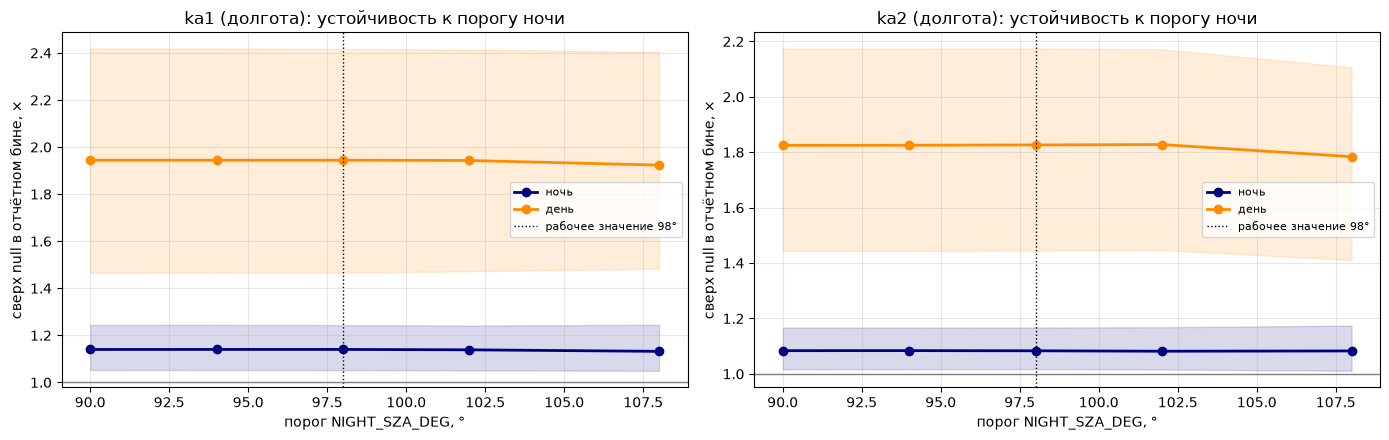

,КА,условия,SZA_порог,бин,сверх null,CI
0,ka1,ночь,90.0,≥3000,1.140,1.05–1.24
1,ka1,ночь,94.0,≥3000,1.140,1.05–1.24
2,ka1,ночь,98.0,≥3000,1.140,1.05–1.24
3,ka1,ночь,102.0,≥3000,1.138,1.05–1.24
4,ka1,ночь,108.0,≥3000,1.132,1.05–1.24
5,ka1,день,90.0,≥3000,1.944,1.47–2.42
6,ka1,день,94.0,≥3000,1.944,1.47–2.42
7,ka1,день,98.0,≥3000,1.944,1.47–2.42
8,ka1,день,102.0,≥3000,1.943,1.47–2.41
9,ka1,день,108.0,≥3000,1.923,1.48–2.40


CPU times: user 26min 58s, sys: 6min 52s, total: 33min 51s
Wall time: 34min 57s


In [13]:
%%time
import traceback

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import wwlln_common as wc
import dose_pipeline as dp

SWEEP_LON_R_KM = [500.0, 1000.0, 2000.0]
SWEEP_LON_DT_MIN = [15, 30, 60]
SWEEP_LON_R_DT_PAIRS = [(r, dt) for r in SWEEP_LON_R_KM for dt in SWEEP_LON_DT_MIN]

sweep_rdt_lon = None
try:
    wc.require_globals(globals(), ['df', 'df_pred', 'DOSE_SC', 'acc_days', 'DOSE_R_KM', 'DOSE_DT_MIN', 'GLAT', 'GLON', 'GDT_MIN', 'NULL_LAGS', 'NULL_SYMMETRIC', 'NULL_SEASON_SAFE', 'NIGHT_SZA_DEG', 'STRATA_SCHEME', 'DOSE_EDGES', 'DOSE_LABELS', 'MIN_STRAT_EXP', 'MIN_REPORT_EXP', 'N_BOOT', 'REF_BIN'], hint='выполните ячейку 94583c9b (основной блок, загрузка) перед этой')
    sweep_rdt_lon = dp.sweep_r_dt(
        df, df_pred, sc_list=DOSE_SC, acc_days=acc_days, r_dt_pairs=SWEEP_LON_R_DT_PAIRS,
        glat=GLAT, glon=GLON, gdt_min=GDT_MIN,
        null_lags=NULL_LAGS, null_symmetric=NULL_SYMMETRIC, null_season_safe=NULL_SEASON_SAFE,
        night_sza_deg=NIGHT_SZA_DEG, strata_scheme='lon', dose_edges=DOSE_EDGES,
    )
except Exception:
    print('!!! ОШИБКА в sweep_rdt_lon — остальные ячейки ноутбука продолжат выполняться:')
    traceback.print_exc()

if sweep_rdt_lon is not None:
    rows = []
    heat = np.full((len(SWEEP_LON_R_KM), len(SWEEP_LON_DT_MIN)), np.nan)
    for ri, r_km in enumerate(SWEEP_LON_R_KM):
        for di, dt_min in enumerate(SWEEP_LON_DT_MIN):
            pair = (r_km, dt_min)
            vals = []
            for si, sc in enumerate(DOSE_SC):
                r = dp.analyze(sweep_rdt_lon[pair], sc=si, n_boot=100, ref_bin=0,
                              min_strat_exp=MIN_STRAT_EXP)
                b = dp.report_bin(r, min_exp=MIN_REPORT_EXP, min_strata=5, ref_bin=0)
                if b is None:
                    continue
                vals.append(r['rrr'][b])
                rows.append({'R, км': r_km, 'Δt, мин': dt_min, 'КА': sc,
                            'бин': DOSE_LABELS[b], 'сверх null': r['rrr'][b],
                            'CI': f"{r['ci_rrr'][0,b]:.2f}–{r['ci_rrr'][1,b]:.2f}"})
            if vals:
                heat[ri, di] = np.mean(vals)

    sweep_rdt_lon_summary = pd.DataFrame(rows)
    display(sweep_rdt_lon_summary.round(3))

    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(heat, cmap='viridis', aspect='auto')
    ax.set_xticks(range(len(SWEEP_LON_DT_MIN)))
    ax.set_xticklabels(SWEEP_LON_DT_MIN)
    ax.set_yticks(range(len(SWEEP_LON_R_KM)))
    ax.set_yticklabels([f'{r:.0f}' for r in SWEEP_LON_R_KM])
    ax.set_xlabel('Δt, мин')
    ax.set_ylabel('R, км')
    ax.set_title('долгота-схема: «сверх null» в отчётном бине, среднее по ka1/ka2')
    for ri in range(len(SWEEP_LON_R_KM)):
        for di in range(len(SWEEP_LON_DT_MIN)):
            if np.isfinite(heat[ri, di]):
                ax.text(di, ri, f'{heat[ri, di]:.2f}', ha='center', va='center',
                        color='white' if heat[ri, di] < np.nanmax(heat) * 0.7 else 'black')
    fig.colorbar(im, ax=ax, label='сверх null, ×')
    fig.tight_layout()
    plt.show()
    plt.close(fig)
else:
    print('sweep_rdt_lon не посчитан — см. traceback выше, эта ячейка пропущена.')

# --- sweep по порогу ночи, схема "долгота" ---
SWEEP_LON_SZA = [90.0, 94.0, 98.0, 102.0, 108.0]
sweep_sza_lon = None
try:
    sweep_sza_lon = dp.sweep_night_sza(
        df, df_pred, sc_list=DOSE_SC, acc_days=acc_days, sza_list=SWEEP_LON_SZA,
        dose_r_km=DOSE_R_KM, dose_dt_min=DOSE_DT_MIN, glat=GLAT, glon=GLON, gdt_min=GDT_MIN,
        null_lags=NULL_LAGS, null_symmetric=NULL_SYMMETRIC, null_season_safe=NULL_SEASON_SAFE,
        strata_scheme='lon', dose_edges=DOSE_EDGES,
    )
except Exception:
    print('!!! ОШИБКА в sweep_sza_lon — остальные ячейки ноутбука продолжат выполняться:')
    traceback.print_exc()

if sweep_sza_lon is not None:
    fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5), squeeze=False)
    rows = []
    for si, sc in enumerate(DOSE_SC):
        ax = axes[0, si]
        for night, lab, color in [(1, 'ночь', 'navy'), (0, 'день', 'darkorange')]:
            ys, ci_lo, ci_hi = [], [], []
            for sza in SWEEP_LON_SZA:
                r = dp.analyze(sweep_sza_lon[sza], sc=si, night=night, n_boot=100, ref_bin=0,
                              min_strat_exp=MIN_STRAT_EXP)
                b = dp.report_bin(r, min_exp=MIN_REPORT_EXP, min_strata=5, ref_bin=0)
                if b is None:
                    ys.append(np.nan); ci_lo.append(np.nan); ci_hi.append(np.nan)
                    continue
                ys.append(r['rrr'][b]); ci_lo.append(r['ci_rrr'][0, b]); ci_hi.append(r['ci_rrr'][1, b])
                rows.append({'КА': sc, 'условия': lab, 'SZA_порог': sza, 'бин': DOSE_LABELS[b],
                            'сверх null': r['rrr'][b],
                            'CI': f"{r['ci_rrr'][0,b]:.2f}–{r['ci_rrr'][1,b]:.2f}"})
            ax.plot(SWEEP_LON_SZA, ys, 'o-', color=color, lw=2, label=lab)
            ax.fill_between(SWEEP_LON_SZA, ci_lo, ci_hi, color=color, alpha=0.15)
        ax.axvline(98.0, color='k', ls=':', lw=1, label='рабочее значение 98°')
        ax.axhline(1.0, color='gray', lw=1)
        ax.set_xlabel('порог NIGHT_SZA_DEG, °')
        ax.set_ylabel('сверх null в отчётном бине, ×')
        ax.set_title(f'{sc} (долгота): устойчивость к порогу ночи')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    sweep_sza_lon_summary = pd.DataFrame(rows)
    display(sweep_sza_lon_summary.round(3))
else:
    print('sweep_sza_lon не посчитан — см. traceback выше, эта ячейка пропущена.')


## 4.8. Footprint и магнитно-сопряжённая точка, схема «долгота»

В §4.5 сопряжённая точка на схеме LST и с лагами только назад дала более слабый эффект: интервал накрывал 1 у обоих аппаратов, footprint был рядом с точкой под спутником. Здесь та же пара геометрий при настройках блока долготы: радиус 1000 км, окно 30 мин, симметричные лаги null. Сначала footprint, затем сопряжённая точка.


Накопители: 81 МБ; сетки строим для 314 дней (схема страт='lon', лаги=(3, 7, 14)±, сезонный фильтр=вкл)
  ... 20/314 дней
  ... 40/314 дней
  ... 60/314 дней
  ... 80/314 дней
  ... 100/314 дней
  ... 120/314 дней
  ... 140/314 дней
  ... 160/314 дней
  ... 180/314 дней
  ... 200/314 дней
  ... 220/314 дней
  ... 240/314 дней
  ... 260/314 дней
  ... 280/314 дней
  ... 300/314 дней
Готово. Экспозиция: 41,985,036 сэмплов, verdict=1: 3,816,529 (9.09%); экспозиция null: 232,113,950 (в среднем 5.53 лага/сутки использовано из 6 возможных)


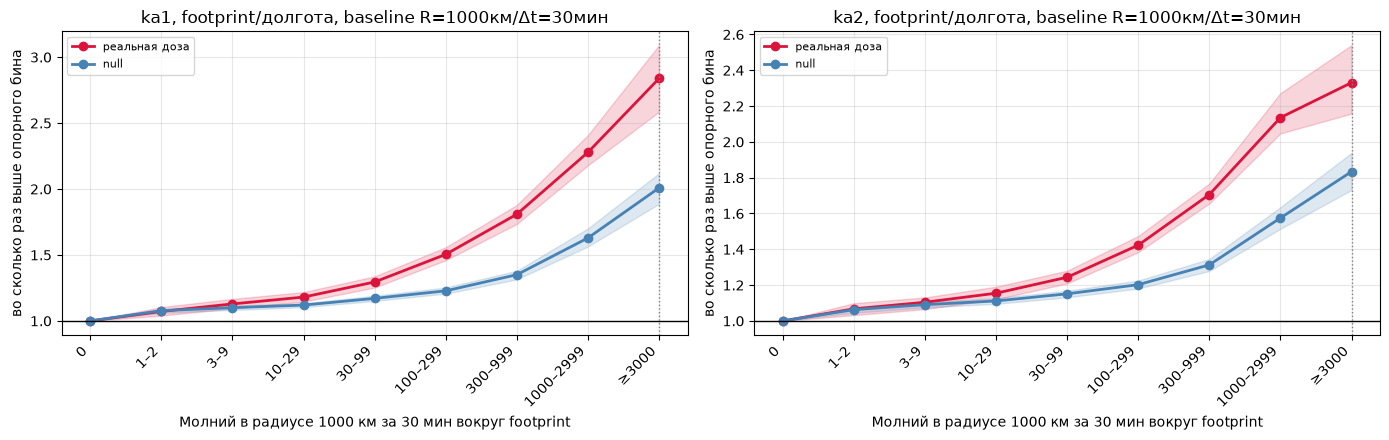

,КА,geometry,бин дозы,рост MH,рост null,сверх null,CI сверх null
0,ka1,"footprint (долгота, baseline)",≥3000,2.838,2.009,1.413,1.32–1.53
1,ka2,"footprint (долгота, baseline)",≥3000,2.331,1.834,1.271,1.17–1.37


CPU times: user 6min 1s, sys: 2min 9s, total: 8min 10s
Wall time: 8min 36s


In [14]:
%%time
# --- footprint, долгота-схема, baseline (R=1000км/Δt=30мин, симметричный null) ---
import traceback

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import wwlln_common as wc
import dose_pipeline as dp

accum_lon_fp = None
try:
    wc.require_globals(globals(), ['df', 'df_pred', 'DOSE_SC', 'acc_days', 'DOSE_R_KM', 'DOSE_DT_MIN', 'GLAT', 'GLON', 'GDT_MIN', 'NULL_LAGS', 'NULL_SEASON_SAFE', 'NIGHT_SZA_DEG', 'DOSE_EDGES', 'DOSE_LABELS', 'MIN_STRAT_EXP', 'MIN_REPORT_EXP', 'N_BOOT', 'REF_BIN'], hint='выполните ячейку 94583c9b (основной блок, загрузка) перед этой')
    accum_lon_fp = dp.run_accumulation(
        df, df_pred, sc_list=DOSE_SC, acc_days=acc_days,
        dose_r_km=DOSE_R_KM, dose_dt_min=DOSE_DT_MIN,
        glat=GLAT, glon=GLON, gdt_min=GDT_MIN,
        null_lags=NULL_LAGS, null_symmetric=True, null_season_safe=NULL_SEASON_SAFE,
        do_energy=False, night_sza_deg=NIGHT_SZA_DEG, strata_scheme='lon',
        geometry='footprint', dose_edges=DOSE_EDGES,
    )
except Exception:
    print('!!! ОШИБКА в accum_lon_fp — остальные ячейки ноутбука продолжат выполняться:')
    traceback.print_exc()

RES_LON_FP = {}
if accum_lon_fp is not None:
    x_geo = np.arange(accum_lon_fp['n_dose'])
    fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5), squeeze=False)
    rows = []
    for si, sc in enumerate(DOSE_SC):
        r = dp.analyze(accum_lon_fp, sc=si, n_boot=N_BOOT, ref_bin=REF_BIN, min_strat_exp=MIN_STRAT_EXP)
        RES_LON_FP[sc] = r
        rb = dp.report_bin(r, min_exp=MIN_REPORT_EXP, min_strata=5, ref_bin=REF_BIN)

        ax = axes[0, si]
        ax.plot(x_geo, r['rr_t'], 'o-', color='crimson', lw=2, label='реальная доза')
        ax.fill_between(x_geo, r['ci_t'][0], r['ci_t'][1], color='crimson', alpha=0.18)
        ax.plot(x_geo, r['rr_n'], 'o-', color='steelblue', lw=2, label='null')
        ax.fill_between(x_geo, r['ci_n'][0], r['ci_n'][1], color='steelblue', alpha=0.18)
        ax.axhline(1.0, color='k', lw=1)
        if rb is not None:
            ax.axvline(rb, color='gray', ls=':', lw=1)
        ax.set_xticks(x_geo)
        ax.set_xticklabels(DOSE_LABELS, rotation=45, ha='right')
        ax.set_xlabel(f'Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин вокруг footprint')
        ax.set_ylabel('во сколько раз выше опорного бина')
        ax.set_title(f'{sc}, footprint/долгота, baseline R={DOSE_R_KM:.0f}км/Δt={DOSE_DT_MIN}мин')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)

        if rb is not None:
            rows.append({'КА': sc, 'geometry': 'footprint (долгота, baseline)',
                        'бин дозы': DOSE_LABELS[rb], 'рост MH': r['rr_t'][rb],
                        'рост null': r['rr_n'][rb], 'сверх null': r['rrr'][rb],
                        'CI сверх null': f"{r['ci_rrr'][0,rb]:.2f}–{r['ci_rrr'][1,rb]:.2f}"})
        else:
            rows.append({'КА': sc, 'geometry': 'footprint (долгота, baseline)', 'бин дозы': 'нет носителя'})
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    display(pd.DataFrame(rows).round(3))
else:
    print('accum_lon_fp не посчитан — см. traceback выше, эта ячейка пропущена.')


Накопители: 81 МБ; сетки строим для 314 дней (схема страт='lon', лаги=(3, 7, 14)±, сезонный фильтр=вкл)
  ... 20/314 дней
  ... 40/314 дней
  ... 60/314 дней
  ... 80/314 дней
  ... 100/314 дней
  ... 120/314 дней
  ... 140/314 дней
  ... 160/314 дней
  ... 180/314 дней
  ... 200/314 дней
  ... 220/314 дней
  ... 240/314 дней
  ... 260/314 дней
  ... 280/314 дней
  ... 300/314 дней
Готово. Экспозиция: 41,985,036 сэмплов, verdict=1: 3,816,529 (9.09%); экспозиция null: 232,113,950 (в среднем 5.53 лага/сутки использовано из 6 возможных)


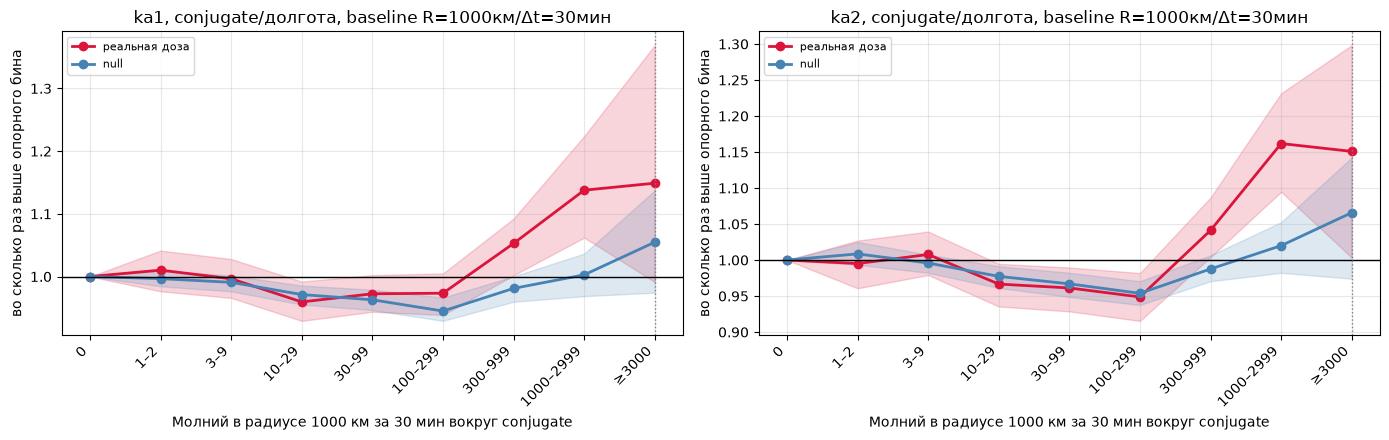

,КА,geometry,бин дозы,рост MH,рост null,сверх null,CI сверх null
0,ka1,"conjugate (долгота, baseline)",≥3000,1.149,1.055,1.089,0.96–1.28
1,ka2,"conjugate (долгота, baseline)",≥3000,1.151,1.066,1.080,0.96–1.21


Сравните эту таблицу с §4.5 (conjugate, LST-схема, R=1000км/Δt=30мин, обычный null, CI пересекал 1.0): показывает, меняет ли схема «долгота» + симметричный null вывод про conjugate на тех же R/Δt.
CPU times: user 6min 2s, sys: 2min 12s, total: 8min 14s
Wall time: 8min 40s


In [15]:
%%time
# --- conjugate, долгота-схема, baseline (R=1000км/Δt=30мин, симметричный null) ---
import traceback

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import wwlln_common as wc
import dose_pipeline as dp

accum_lon_cj = None
try:
    wc.require_globals(globals(), ['df', 'df_pred', 'DOSE_SC', 'acc_days', 'DOSE_R_KM', 'DOSE_DT_MIN', 'GLAT', 'GLON', 'GDT_MIN', 'NULL_LAGS', 'NULL_SEASON_SAFE', 'NIGHT_SZA_DEG', 'DOSE_EDGES', 'DOSE_LABELS', 'MIN_STRAT_EXP', 'MIN_REPORT_EXP', 'N_BOOT', 'REF_BIN'], hint='выполните ячейку 94583c9b (основной блок, загрузка) перед этой')
    accum_lon_cj = dp.run_accumulation(
        df, df_pred, sc_list=DOSE_SC, acc_days=acc_days,
        dose_r_km=DOSE_R_KM, dose_dt_min=DOSE_DT_MIN,
        glat=GLAT, glon=GLON, gdt_min=GDT_MIN,
        null_lags=NULL_LAGS, null_symmetric=True, null_season_safe=NULL_SEASON_SAFE,
        do_energy=False, night_sza_deg=NIGHT_SZA_DEG, strata_scheme='lon',
        geometry='conjugate', dose_edges=DOSE_EDGES,
    )
except Exception:
    print('!!! ОШИБКА в accum_lon_cj — остальные ячейки ноутбука продолжат выполняться:')
    traceback.print_exc()

RES_LON_CJ = {}
if accum_lon_cj is not None:
    x_geo = np.arange(accum_lon_cj['n_dose'])
    fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5), squeeze=False)
    rows = []
    for si, sc in enumerate(DOSE_SC):
        r = dp.analyze(accum_lon_cj, sc=si, n_boot=N_BOOT, ref_bin=REF_BIN, min_strat_exp=MIN_STRAT_EXP)
        RES_LON_CJ[sc] = r
        rb = dp.report_bin(r, min_exp=MIN_REPORT_EXP, min_strata=5, ref_bin=REF_BIN)

        ax = axes[0, si]
        ax.plot(x_geo, r['rr_t'], 'o-', color='crimson', lw=2, label='реальная доза')
        ax.fill_between(x_geo, r['ci_t'][0], r['ci_t'][1], color='crimson', alpha=0.18)
        ax.plot(x_geo, r['rr_n'], 'o-', color='steelblue', lw=2, label='null')
        ax.fill_between(x_geo, r['ci_n'][0], r['ci_n'][1], color='steelblue', alpha=0.18)
        ax.axhline(1.0, color='k', lw=1)
        if rb is not None:
            ax.axvline(rb, color='gray', ls=':', lw=1)
        ax.set_xticks(x_geo)
        ax.set_xticklabels(DOSE_LABELS, rotation=45, ha='right')
        ax.set_xlabel(f'Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин вокруг conjugate')
        ax.set_ylabel('во сколько раз выше опорного бина')
        ax.set_title(f'{sc}, conjugate/долгота, baseline R={DOSE_R_KM:.0f}км/Δt={DOSE_DT_MIN}мин')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)

        if rb is not None:
            rows.append({'КА': sc, 'geometry': 'conjugate (долгота, baseline)',
                        'бин дозы': DOSE_LABELS[rb], 'рост MH': r['rr_t'][rb],
                        'рост null': r['rr_n'][rb], 'сверх null': r['rrr'][rb],
                        'CI сверх null': f"{r['ci_rrr'][0,rb]:.2f}–{r['ci_rrr'][1,rb]:.2f}"})
        else:
            rows.append({'КА': sc, 'geometry': 'conjugate (долгота, baseline)', 'бин дозы': 'нет носителя'})
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    display(pd.DataFrame(rows).round(3))
    print('Сравните эту таблицу с §4.5 (conjugate, LST-схема, R=1000км/Δt=30мин, обычный null, '
          'CI пересекал 1.0): показывает, меняет ли схема «долгота» + симметричный null вывод '
          'про conjugate на тех же R/Δt.')
else:
    print('accum_lon_cj не посчитан — см. traceback выше, эта ячейка пропущена.')


### Все бины дозы, три геометрии

Сравнения выше сняты на бине «≥3000». По диагностике осей вес этого бина собран в немногих полосах долготы, и носитель там тонкий. Ниже кривая MH / null для точки под спутником, footprint и сопряжённой точки по всем бинам дозы, и число страт с носителем на каждом бине. Берутся готовые `RES_LON`, `RES_LON_FP` и `RES_LON_CJ`.


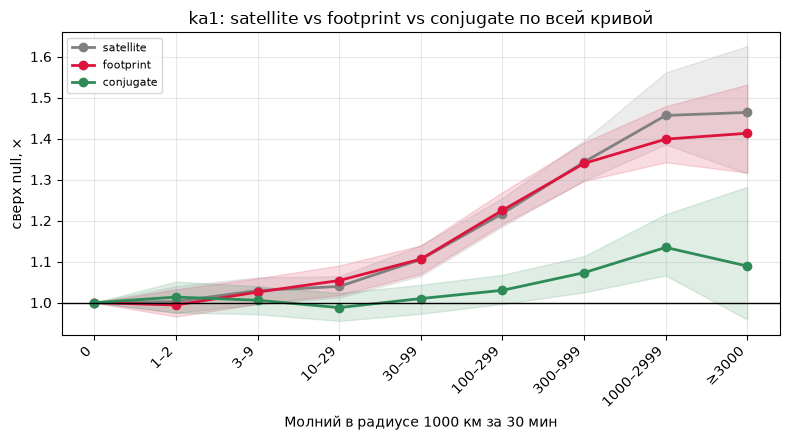

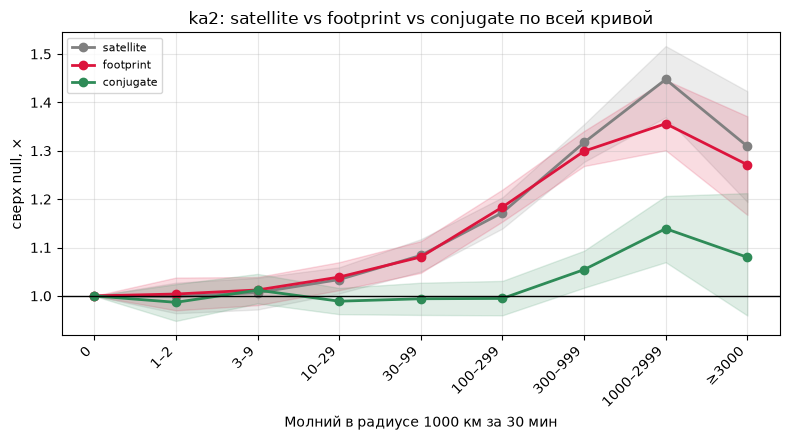

,КА,бин,satellite: сверх null,satellite: страт,footprint: сверх null,footprint: страт,conjugate: сверх null,conjugate: страт
0,ka1,1–2,1.00,435,0.99,433,1.01,445
1,ka1,3–9,1.03,459,1.03,460,1.01,482
2,ka1,10–29,1.04,445,1.05,444,0.99,482
3,ka1,30–99,1.11,427,1.11,428,1.01,464
4,ka1,100–299,1.22,371,1.23,377,1.03,398
5,ka1,300–999,1.34,284,1.34,294,1.07,317
6,ka1,1000–2999,1.46,122,1.40,133,1.13,143
7,ka1,≥3000,1.46,28,1.41,40,1.09,33
8,ka2,1–2,1.00,423,1.00,431,0.99,449
9,ka2,3–9,1.01,456,1.01,465,1.01,491


Смотрите на бины, где у ВСЕХ геометрий ещё приличное число страт (не 0-1) — если на таком бине conjugate по-прежнему заметно ниже footprint/satellite, разница — не следствие нехватки данных на хвосте, а самостоятельный результат.


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_deps = ['RES_LON', 'DOSE_SC', 'DOSE_LABELS', 'REF_BIN']
_missing = [n for n in _deps if n not in globals()]
_have_fp = 'RES_LON_FP' in globals() and RES_LON_FP
_have_cj = 'RES_LON_CJ' in globals() and RES_LON_CJ
if _missing:
    print(f'Пропущено: не определено {_missing}. Выполните §4.4 перед этой ячейкой.')
elif not (_have_fp or _have_cj):
    print('RES_LON_FP/RES_LON_CJ не найдены \u2014 выполните §4.8 (footprint и/или conjugate, baseline) перед этой.')
else:
    geo_res = {'satellite': RES_LON}
    if _have_fp:
        geo_res['footprint'] = RES_LON_FP
    if _have_cj:
        geo_res['conjugate'] = RES_LON_CJ
    colors = {'satellite': 'gray', 'footprint': 'crimson', 'conjugate': 'seagreen'}

    for si, sc in enumerate(DOSE_SC):
        fig, ax = plt.subplots(figsize=(8, 4.5))
        for geom, res_dict in geo_res.items():
            r = res_dict.get(sc)
            if r is None:
                continue
            x = np.arange(len(r['rrr']))
            ax.plot(x, r['rrr'], 'o-', color=colors[geom], lw=2, label=geom)
            ax.fill_between(x, r['ci_rrr'][0], r['ci_rrr'][1], color=colors[geom], alpha=0.15)
        ax.axhline(1.0, color='k', lw=1)
        ax.set_xticks(np.arange(len(DOSE_LABELS)))
        ax.set_xticklabels(DOSE_LABELS, rotation=45, ha='right')
        ax.set_ylabel('сверх null, \u00d7')
        ax.set_xlabel(f'Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин')
        ax.set_title(f'{sc}: satellite vs footprint vs conjugate по всей кривой')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
        fig.tight_layout()
        plt.show()
        plt.close(fig)

    rows = []
    for si, sc in enumerate(DOSE_SC):
        for k, lab in enumerate(DOSE_LABELS):
            if k == REF_BIN:
                continue
            row = {'КА': sc, 'бин': lab}
            for geom, res_dict in geo_res.items():
                r = res_dict.get(sc)
                if r is None or not np.isfinite(r['rrr'][k]):
                    row[f'{geom}: сверх null'] = np.nan
                    row[f'{geom}: страт'] = 0
                    continue
                row[f'{geom}: сверх null'] = r['rrr'][k]
                row[f'{geom}: страт'] = int(r['nst'][k])
            rows.append(row)
    geo_curve_compare = pd.DataFrame(rows)
    display(geo_curve_compare.round(2))
    print('Смотрите на бины, где у ВСЕХ геометрий ещё приличное число страт (не 0-1) \u2014 '
          'если на таком бине conjugate по-прежнему заметно ниже footprint/satellite, разница \u2014 '
          'не следствие нехватки данных на хвосте, а самостоятельный результат.')
